**Author:**

Kumar Jayant

# Drive Out Subjectivity, Build What Customers Value: The Algorithmic Way to New Offer Development

Companion notebook to the aimldl.io post *Drive Out Subjectivity, Build What Customers Value: The Algorithmic Way to New Offer Development*. The blog explains the method; this notebook runs Step 2, the product preference analytics, end to end.

**Data:** [jPhone: Customer Preferences for New Products](https://www.kaggle.com/datasets/krjynt/jphone-customer-preferences-for-new-products) (CC0: Public Domain). It has three files:
- `jphone_customer_preferences.csv`: 300 simulated customers, one row each, with no missing values. Each row holds the customer's segment, how much each of six attributes matters to them (brand, price, camera, battery, screen, memory; adds up to 100), how much they like each level of each attribute (1 to 7), whether they trade off or screen first, and deal-breakers for the 108 who screen first.
- `jphone_prototypes.csv`: six jPhone prototypes, P1 to P6, to test.
- `competitors.csv`: two rival phones already on sale, Phone X and Phone Y.

The data is fully simulated. It is used as an illustration of the approach, not as evidence about the phone market.

**Method Used:** customers choose in two ways. Some **trade off** (compensatory): a strong camera can make up for a weak battery. Others **screen first** (non-compensatory): fail one deal-breaker and the product is out, however good the rest is. This notebook scores every product for every customer under both rules, turns scores into purchase probabilities with a **logit** model, and builds a share index and the maximum affordable cost for each prototype.

**What this notebook does**
1. **Settings:** one cell lists the attributes, the files, and four business assumptions: today's market shares of the rival phones, the target margin, what screeners do when every product fails their deal-breakers, and whether prototypes launch one at a time or together. Change only this cell to run the notebook on your own data or assumptions.
2. **Checks the input:** stops with a plain-language message if a column is missing, has blanks, or if a customer's importances don't add up to 100.
3. **Sets up the market:** the six prototypes plus the two rival phones, described on the same attributes.
4. **Predicts each customer's choice under both rules:** trade-off only (importance × rating, summed), and screen-then-trade-off (deal-breakers first, then score what is left). Shows how many customers change their pick.
5. **Turns scores into likelihoods:** a logit converts scores into a probability of buying each product, tuned so the model reproduces today's market shares of the rival phones.
6. **Estimates share and affordable cost:** launches each prototype against the rivals, averages purchase probabilities into a share index, and works out the most each prototype can cost to make (price minus target margin).
7. **Compares the shortlist:** share against price, cost headroom, and a split by segment. The notebook stops short of picking; that is a business call.
8. **Stress-tests the result:** re-runs the shortlist if rivals cut prices, if deal-breakers get stricter, if the market is more or less price-sensitive, and at a different target margin. Shows whether the winner holds.
9. **Exports** the share and cost table (`prototype_share_index.csv`) and the stress-test results (`stress_test_results.csv`).

**Using your own data:** one row per customer, no missing values. You need importances that add up to 100, a rating for every attribute level, and, optionally, a decision-rule flag with deal-breakers. Describe your products and the rivals' on the same attributes. Fill in the settings cell and run all.

In [40]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import glob, os
import kagglehub
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm
from matplotlib.patches import FancyBboxPatch
import matplotlib.ticker as mticker
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import math
from IPython.display import Math
import matplotlib.pyplot as plt
from matplotlib.patches import Patch


pd.set_option('display.float_format', lambda v: f'{v:,.2f}')
plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False, 'axes.spines.right': False})

## Settings

Every assumption the analysis uses, in one place. Change a value here and run all cells again; nothing else needs editing.


In [ ]:
# ===== Settings: all assumptions in one place =====

# Step 2c-1 / 2d: logit sensitivity. Fixed here (simulated data), not tuned to market shares.
C = 0.0139

# Market share chart (2c-1): cut-offs for prototypes
LAUNCH_MIN  = 0.13    # >= 13%           -> top contender for launch
LIBRARY_MIN = 0.10    # >= 10% and < 13% -> development library

# 2c-3 Elimination by aspects: a level clears the bar if rated at least this (out of 7)
EBA_BAR = 5

# 2c-4 Conjunctive: what a screener does if every product fails a deal-breaker
NO_PRODUCT_LEFT = "none"   # "none" = buys nothing; "best" = ignores the screen

# 2c-5 Disjunctive: "outstanding" = rated at least DISJ_BAR, on the top DISJ_TOP attributes
DISJ_BAR = 6
DISJ_TOP = 2

# 2c summary: consensus rule
CONSENSUS_SHARE = 0.10   # a rule "backs" a product if it wins at least 10% of customers
CORE_MIN = 4             # backed by 4 or 5 of the 5 rules -> final shortlist
WATCH_MIN = 2            # backed by 2 or 3 rules          -> development library

# Step 2e: target margin and the shortlist launched on its own against the rivals
TARGET_MARGIN = 0.30
SHORTLIST = ["jPhone P4", "jPhone P1", "jPhone P5"]


## 0. Import the dataset

In [41]:
## 1. Import the dataset
# Data: pulled straight from Kaggle (works in Colab and in Kaggle notebooks; cached after the first download).
# To run on your own file instead, comment out the next two lines and set DATA_PATH to your CSV, e.g.
# DATA_PATH = '/content/my_customers.csv'

matches = glob.glob("/kaggle/input/**/jphone_customer_preferences.csv", recursive=True)
if matches:
    DATA_DIR = os.path.dirname(matches[0])
else:
    # Download the dataset automatically using kagglehub if not running on Kaggle
    print("Downloading dataset from Kaggle...")
    DATA_DIR = kagglehub.dataset_download("krjynt/jphone-customer-preferences-for-new-products")

print("Reading data from:", DATA_DIR)

customers = pd.read_csv(os.path.join(DATA_DIR, "jphone_customer_preferences.csv"))
prototypes = pd.read_csv(os.path.join(DATA_DIR, "jphone_prototypes.csv"))
competitors = pd.read_csv(os.path.join(DATA_DIR, "competitors.csv"))

Using Colab cache for faster access to the 'jphone-customer-preferences-for-new-products' dataset.
Reading data from: /kaggle/input/jphone-customer-preferences-for-new-products


In [42]:
customers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 29 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   customer_id              300 non-null    object 
 1   segment                  300 non-null    object 
 2   imp_brand                300 non-null    int64  
 3   imp_price                300 non-null    int64  
 4   imp_camera               300 non-null    int64  
 5   imp_battery              300 non-null    int64  
 6   imp_screen               300 non-null    int64  
 7   imp_memory               300 non-null    int64  
 8   brand_jPhone             300 non-null    int64  
 9   brand_X                  300 non-null    int64  
 10  brand_Y                  300 non-null    int64  
 11  r_price_20k              300 non-null    int64  
 12  r_price_25k              300 non-null    int64  
 13  r_price_30k              300 non-null    int64  
 14  r_cam_basic              3

In [43]:
prototypes.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6 entries, 0 to 5
Data columns (total 8 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   product  6 non-null      object
 1   brand    6 non-null      object
 2   role     6 non-null      object
 3   price    6 non-null      int64 
 4   camera   6 non-null      object
 5   battery  6 non-null      object
 6   screen   6 non-null      object
 7   memory   6 non-null      object
dtypes: int64(1), object(7)
memory usage: 516.0+ bytes


In [44]:
competitors.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   product  2 non-null      object
 1   brand    2 non-null      object
 2   role     2 non-null      object
 3   price    2 non-null      int64 
 4   camera   2 non-null      object
 5   battery  2 non-null      object
 6   screen   2 non-null      object
 7   memory   2 non-null      object
dtypes: int64(1), object(7)
memory usage: 260.0+ bytes


In [45]:
customers.head()

,customer_id,segment,imp_brand,imp_price,imp_camera,imp_battery,imp_screen,imp_memory,brand_jPhone,brand_X,...,r_scr_6_1,r_scr_6_5,r_scr_6_8,r_mem_128,r_mem_256,r_mem_512,decision_rule,dealbreaker_max_price,dealbreaker_min_battery,dealbreaker_min_memory
0,C001,Power user,7,21,6,10,17,39,5,6,...,2,4,7,2,5,7,Trade off,NaN,NaN,NaN
1,C002,Power user,9,18,13,8,32,20,3,6,...,2,4,6,1,6,6,Trade off,NaN,NaN,NaN
2,C003,Battery first,8,24,19,34,7,8,4,6,...,3,5,4,4,5,6,Trade off,NaN,NaN,NaN
3,C004,Camera lover,13,8,37,21,8,13,3,5,...,4,5,4,5,5,5,Trade off,NaN,NaN,NaN
4,C005,Value seeker,20,47,9,10,3,11,3,6,...,4,5,5,4,5,5,Screen first,"30,000.00",2 days,128 GB


## Step 1: The importance and ratings table (already done)

In the blog, Step 1 is where you research your customers. Here that work is already done: the dataset holds the importance and ratings table for 300 customers.

For each customer, the table has two things:

- **Importance:** how much each attribute matters to them, split across brand, price, camera, battery, screen and memory. These add up to 100.
- **Ratings:** how much they like each level of each attribute, on a scale of 1 to 7. For example, how much they like a ₹20k price against a ₹30k price, or a "Good" camera against the "Best".

Two more columns describe *how* they choose:

- **Decision rule:** whether they trade off (compensatory) or screen first (non-compensatory).
- **Deal-breakers:** for those who screen first, the most they will pay, the least battery life they will accept, and the least memory. These are blank for those who trade off.

**What the cells below do**

1. **Show one customer as an example:** their segment, importances, ratings and decision rule, laid out so the row reads like a short profile.
2. **Check the importances:** confirm every customer's importances add up to 100. If any don't, the notebook stops and lists them.
3. **Summarise the table:** customers by segment, how many trade off and how many screen first, and the average importance of each attribute.

> **On your own data:** this table is what your own customer research produces. With simple research, you ask customers to split 100 points across the attributes and rate each level. With a conjoint study, you work the values out from the choices customers make between whole products. Either way, once you have this table, everything below runs unchanged.

In [46]:
# Attributes, their importance column, and their levels (label -> rating column)
ATTRIBUTES = {
    "Brand":   ("imp_brand",   {"jPhone": "brand_jPhone", "Phone X": "brand_X", "Phone Y": "brand_Y"}),
    "Price":   ("imp_price",   {"₹20k": "r_price_20k", "₹25k": "r_price_25k", "₹30k": "r_price_30k"}),
    "Camera":  ("imp_camera",  {"Basic": "r_cam_basic", "Good": "r_cam_good", "Best": "r_cam_best"}),
    "Battery": ("imp_battery", {"1 day": "r_bat_1day", "2 days": "r_bat_2days"}),
    "Screen":  ("imp_screen",  {'6.1"': "r_scr_6_1", '6.5"': "r_scr_6_5", '6.8"': "r_scr_6_8"}),
    "Memory":  ("imp_memory",  {"128 GB": "r_mem_128", "256 GB": "r_mem_256", "512 GB": "r_mem_512"}),
}
IMP_COLS = [imp for imp, _ in ATTRIBUTES.values()]

def customer_profile(cid):
    """Show one customer's importance and ratings as a short, readable profile."""
    row = customers.loc[customers["customer_id"] == cid].iloc[0]
    print(f"Customer {cid}  |  Segment: {row['segment']}  |  Decision rule: {row['decision_rule']}")
    if row["decision_rule"] == "Screen first":
        print(f"Deal-breakers: price up to ₹{row['dealbreaker_max_price']:,.0f}, "
              f"battery at least {row['dealbreaker_min_battery']}, "
              f"memory at least {row['dealbreaker_min_memory']}")
    table = pd.DataFrame(
        [{"Attribute": attr,
          "Importance (of 100)": row[imp],
          "Ratings by level (1-7)": "   ".join(f"{lvl}: {row[col]}" for lvl, col in levels.items())}
         for attr, (imp, levels) in ATTRIBUTES.items()]
    ).sort_values("Importance (of 100)", ascending=False)
    return table.style.hide(axis="index")

# Pick the first customer who screens first, so the example shows deal-breakers too
example_id = customers.loc[customers["decision_rule"] == "Screen first", "customer_id"].iloc[0]
customer_profile(example_id)

Customer C005  |  Segment: Value seeker  |  Decision rule: Screen first
Deal-breakers: price up to ₹30,000, battery at least 2 days, memory at least 128 GB


Attribute,Importance (of 100),Ratings by level (1-7)
Price,47,₹20k: 7 ₹25k: 7 ₹30k: 2
Brand,20,jPhone: 3 Phone X: 6 Phone Y: 5
Memory,11,128 GB: 4 256 GB: 5 512 GB: 5
Battery,10,1 day: 2 2 days: 6
Camera,9,Basic: 2 Good: 3 Best: 6
Screen,3,"6.1"": 4 6.5"": 5 6.8"": 5"


In [47]:
# check that importances add up to 100

imp_total = customers[IMP_COLS].sum(axis=1)
not_100 = imp_total != 100
bad = customers.loc[not_100, ["customer_id"] + IMP_COLS].copy()
bad["Total"] = imp_total[not_100]

if len(bad) > 0:
    print(f"{len(bad)} customer(s) have importances that don't add up to 100:")
    display(bad)
    raise ValueError("Fix the importances above before going further.")
print(f"Check passed: all {len(customers)} customers' importances add up to 100.")

Check passed: all 300 customers' importances add up to 100.


In [48]:
# Summarise the table

by_segment = (customers.groupby("segment").size().rename("Customers")
              .sort_values(ascending=False).to_frame())
by_segment["Share"] = (by_segment["Customers"] / len(customers)).map("{:.0%}".format)

by_rule = customers["decision_rule"].value_counts().rename("Customers").to_frame()
by_rule["Share"] = (by_rule["Customers"] / len(customers)).map("{:.0%}".format)

avg_importance = (customers[IMP_COLS].mean().round(1)
                  .rename(lambda c: c.replace("imp_", "").capitalize())
                  .sort_values(ascending=False).rename("Average importance (of 100)").to_frame())

print("Customers by segment");          display(by_segment)
print("How customers decide");          display(by_rule)
print("What matters most, on average"); display(avg_importance)

Customers by segment


,Customers,Share
segment,,
Value seeker,89,30%
Power user,79,26%
Camera lover,74,25%
Battery first,58,19%


How customers decide


,Customers,Share
decision_rule,,
Trade off,192,64%
Screen first,108,36%


What matters most, on average


,Average importance (of 100)
Price,22.20
Camera,20.20
Battery,17.90
Memory,17.10
Screen,11.70
Brand,10.90


## Step 2a: List the products to test

The first step of the analytics is to decide which products go into the test.

A full design would test **every combination of attribute levels**. With 3 prices, 3 cameras, 2 battery lives, 3 screen sizes and 3 memory sizes, that is 162 possible jPhones. Most teams don't test them all. Some combinations can't be built, some can't be built at a sensible cost, and some make no sense to sell. So the team shortlists the ones it considers feasible.

Here the team has shortlisted **six prototypes, P1 to P6**, each built around a different idea of what customers might want.

> **On your own data:** list either every combination your team could build, or your shortlist, described on exactly the same attributes and levels as the ratings table. A product with a level customers didn't rate can't be scored.

In [49]:
# Load the prototypes if the setup cell hasn't
if "prototypes" not in globals():
    prototypes = pd.read_csv(os.path.join(DATA_DIR, "jphone_prototypes.csv"))

# A short description of what each prototype is designed to be
PROFILE = {
    "jPhone P1": "Value",
    "jPhone P2": "Camera",
    "jPhone P3": "All-rounder",
    "jPhone P4": "Flagship",
    "jPhone P5": "Storage on a budget",
    "jPhone P6": "Compact premium",
}

shortlist = prototypes.assign(
    Profile=prototypes["product"].map(PROFILE),
    Price=prototypes["price"].map(lambda p: f"₹{p/1000:.0f}k"),
)[["product", "Profile", "Price", "camera", "battery", "screen", "memory"]]
shortlist.columns = ["Prototype", "Profile", "Price", "Camera", "Battery", "Screen", "Memory"]
display(shortlist.style.hide(axis="index"))

# How many phones a full design would test: every combination of levels (brand is fixed as jPhone)
n_levels = {attr: len(levels) for attr, (_, levels) in ATTRIBUTES.items() if attr != "Brand"}
full_design = math.prod(n_levels.values())
print(" × ".join(f"{n} {a.lower()}" for a, n in n_levels.items()), f"= {full_design} possible jPhones.")
print(f"The team has shortlisted {len(prototypes)} of them to test.")

Prototype,Profile,Price,Camera,Battery,Screen,Memory
jPhone P1,Value,₹20k,Good,2 days,"6.5""",128 GB
jPhone P2,Camera,₹25k,Best,1 day,"6.5""",256 GB
jPhone P3,All-rounder,₹25k,Good,2 days,"6.8""",256 GB
jPhone P4,Flagship,₹30k,Best,2 days,"6.8""",512 GB
jPhone P5,Storage on a budget,₹20k,Basic,2 days,"6.1""",256 GB
jPhone P6,Compact premium,₹30k,Best,1 day,"6.1""",512 GB


3 price × 3 camera × 2 battery × 3 screen × 3 memory = 162 possible jPhones.
The team has shortlisted 6 of them to test.


3 price × 3 camera × 2 battery × 3 screen × 3 memory = 162 possible jPhones.

The team has shortlisted 6 of them to test.

## Step 2b: Set up the market

A prototype is never chosen in a vacuum. Customers compare it with what is already on the shelf. So the market for this test is the six jPhone prototypes **plus the two rival phones already on sale, Phone X and Phone Y**.

The rivals are described on exactly the same six attributes as the prototypes, **brand included**. Brand matters because customers rated each brand too, and some like Phone X's brand more than jPhone's. A new brand has to earn its place against an established one.

The cell below also links every product's levels to the matching ratings in the customer table, and checks that no product uses a level customers didn't rate.

> **On your own data:** add the competitor products your customers actually weigh you against, not every product in the category. Describe them on the same attributes and levels as your own.

In [50]:
# Load the competitors if the setup cell hasn't
if "competitors" not in globals():
    competitors = pd.read_csv(os.path.join(DATA_DIR, "competitors.csv"))

# The market = our six prototypes + the two rival phones already on sale
market = pd.concat([prototypes, competitors], ignore_index=True)

# Link each product's level to the matching rating column in the customer table
LEVEL_TO_COLUMN = {
    "brand":   lambda v: f"brand_{v}",                               # jPhone -> brand_jPhone, X -> brand_X
    "price":   lambda v: f"r_price_{int(v) // 1000}k",               # 25000 -> r_price_25k
    "camera":  lambda v: f"r_cam_{v.lower()}",                       # Good -> r_cam_good
    "battery": lambda v: f"r_bat_{v.replace(' ', '')}",              # 2 days -> r_bat_2days
    "screen":  lambda v: "r_scr_" + v.strip('"').replace(".", "_"),  # 6.5" -> r_scr_6_5
    "memory":  lambda v: f"r_mem_{v.split()[0]}",                    # 256 GB -> r_mem_256
}
for attr, to_col in LEVEL_TO_COLUMN.items():
    market[f"col_{attr}"] = market[attr].map(to_col)

# Check: every product must use levels that customers actually rated
rating_cols = [c for c in market.columns if c.startswith("col_")]
missing = {(p, market.at[i, c]) for c in rating_cols for i, p in market["product"].items()
           if market.at[i, c] not in customers.columns}
if missing:
    raise ValueError(f"These product levels have no customer ratings: {sorted(missing)}")
print(f"Check passed: all {len(market)} products use levels that customers rated.")

# Show the market, with the rivals shaded
view = market.assign(
    Brand=market["brand"].replace({"X": "Phone X", "Y": "Phone Y"}),
    Price=market["price"].map(lambda p: f"₹{p/1000:.0f}k"),
)[["product", "role", "Brand", "Price", "camera", "battery", "screen", "memory"]]
view.columns = ["Product", "Role", "Brand", "Price", "Camera", "Battery", "Screen", "Memory"]
display(view.style.hide(axis="index")
            .apply(lambda r: ["background-color:#fdf0e4" if r["Role"] == "Competitor" else ""] * len(r), axis=1))

Check passed: all 8 products use levels that customers rated.


Product,Role,Brand,Price,Camera,Battery,Screen,Memory
jPhone P1,Prototype,jPhone,₹20k,Good,2 days,"6.5""",128 GB
jPhone P2,Prototype,jPhone,₹25k,Best,1 day,"6.5""",256 GB
jPhone P3,Prototype,jPhone,₹25k,Good,2 days,"6.8""",256 GB
jPhone P4,Prototype,jPhone,₹30k,Best,2 days,"6.8""",512 GB
jPhone P5,Prototype,jPhone,₹20k,Basic,2 days,"6.1""",256 GB
jPhone P6,Prototype,jPhone,₹30k,Best,1 day,"6.1""",512 GB
Phone X,Competitor,Phone X,₹25k,Good,2 days,"6.5""",128 GB
Phone Y,Competitor,Phone Y,₹30k,Best,1 day,"6.8""",256 GB


## Step 2c: Predict each customer's choice

This is the heart of the method. Each customer "shops" the market of eight phones, and we predict which one they would pick.

Customers don't all decide the same way. The blog describes five decision rules: one compensatory, where customers **trade off**, and four non-compensatory, where they **screen**. We run each rule in turn:

| Cell | Rule | How the customer decides |
|---|---|---|
| 2c-1 | Compensatory: weighted additive | Weighs every attribute and adds it up. Strengths make up for weaknesses. |
| 2c-2 | Lexicographic | Looks only at what matters most; the next attribute just breaks ties. |
| 2c-3 | Elimination by aspects | Sets a bar on each attribute, most important first, and knocks out products below it. |
| 2c-4 | Conjunctive | Must pass every test. Uses the screeners' own deal-breakers. |
| 2c-5 | Disjunctive | Must excel at one thing the customer cares about. |

**What the data gives us, and what it doesn't.** The dataset records whether each customer trades off or screens first, and the deal-breakers of the 108 who screen. Those deal-breakers are minimums on price, battery and memory, which is a **conjunctive** screen, so 2c-4 is the realistic model of this market. For the other three non-compensatory rules, we ask *"what if every customer decided this way?"*. If the same product wins whichever rule customers follow, we can be more confident in the pick.

Whenever a rule leaves more than one product standing, the customer's weighted score breaks the tie.

### 2c-1. Compensatory approach: weighted additive

The customer weighs each phone on everything that matters to them, gives more weight to what matters most, and adds it up. A weaker battery can be made up by a great camera.

**1. Utility.** For each customer and each product:

> u = Σ (importance of the attribute × rating of the product's level on that attribute)

We work it out in full for the first customer, then repeat for every customer.

**2. Max choice.** The product with the highest utility is the customer's first choice.

**3. Purchase probability.** Real customers don't always pick the top score, especially when two products are close. The logit formula turns utilities into a probability of buying each product:

> P(product) = exp(c × u) ÷ Σ exp(c × u) over all products

Here **c = 0.0139**. The larger c is, the more surely customers pick their top product. Step 2d tunes c so the model matches today's market shares.

**4. Share.** Averaging each product's probability over all customers gives its predicted share.

In [51]:
# ===== 2c-1. Compensatory: weighted additive utility, then logit probabilities =====
# C is set in the Settings cell at the top
ATTR_KEYS = ["brand", "price", "camera", "battery", "screen", "memory"]
cust = customers.set_index("customer_id")
products = market["product"].tolist()
short = {p: p.replace("jPhone ", "").replace("Phone ", "") for p in products}   # P1..P6, X, Y

# --- 1. Utility = sum of (importance x rating) for every customer and product ---
scores = pd.DataFrame(index=cust.index)
for _, prod in market.iterrows():
    scores[prod["product"]] = sum(cust[f"imp_{a}"] * cust[prod[f"col_{a}"]] for a in ATTR_KEYS)

# Worked example: the first customer, product by product
cid = cust.index[0]
print(f"Utility for customer {cid}  (brand + price + camera + battery + screen + memory):")
for _, prod in market.iterrows():
    terms = " + ".join(f"{cust.at[cid, f'imp_{a}']} \\times {cust.at[cid, prod[f'col_{a}']]}" for a in ATTR_KEYS)
    display(Math(f"u_{{{short[prod['product']]}}} = {terms} = {scores.at[cid, prod['product']]:.0f}"))

# --- 2. Repeat for every customer: the highest utility is the max choice ---
U = scores.rename(columns=lambda p: "U" + short[p]).astype(int)
U["maxchoice"] = scores.idxmax(axis=1).map(short)
print("\nUtilities for every customer (first 10 shown):")
display(U.head(10))

# --- 3. Logit: P(product) = exp(c x u) / sum of exp(c x u) over all products ---
expu = np.exp(C * scores)
probs = expu.div(expu.sum(axis=1), axis=0)
P = probs.rename(columns=lambda p: "P" + short[p])

print(f"\nPurchase probabilities with c = {C} (first 10 shown):")
display(U.join(P).head(10).round(2))

# --- 4. Average the probabilities = predicted share ---
shares = pd.DataFrame({
    "Share by max choice": U["maxchoice"].value_counts(normalize=True).reindex(short.values()).fillna(0).values,
    "Share by probability (Ave)": probs.mean().values,
}, index=list(short.values())).T
print(f"\nAveraging the probabilities over all {len(cust)} customers gives the predicted shares:")
display(shares.style.format("{:.0%}"))

# --- Kept for the rules below ---
PICKS = {"Compensatory": scores.idxmax(axis=1)}
IMP = cust[[f"imp_{a}" for a in ATTR_KEYS]].to_numpy(float)
R = np.stack([cust[[market.at[p, f"col_{a}"] for a in ATTR_KEYS]].to_numpy(float)
              for p in range(len(products))], axis=1)
ATTR_NAME = {a: a.capitalize() for a in ATTR_KEYS}

def pick_best(allowed):
    """Highest utility among the products a customer still allows (True/False table)."""
    s = scores.where(allowed)
    none_left = s.isna().all(axis=1)
    return s.fillna(-np.inf).idxmax(axis=1).where(~none_left, "Buys nothing")

def first_choice(picks, label):
    t = picks.value_counts().reindex(products + ["Buys nothing"]).fillna(0).astype(int).rename(label).to_frame()
    t[f"{label} (%)"] = (t[label] / len(picks) * 100).round(0).astype(int)
    return t

Utility for customer C001  (brand + price + camera + battery + screen + memory):


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

... (5 outputs left out)


Purchase probabilities with c = 0.0139 (first 10 shown):


,UP1,UP2,UP3,UP4,UP5,UP6,UX,UY,maxchoice,PP1,PP2,PP3,PP4,PP5,PP6,PX,PY
customer_id,,,,,,,,,,,,,,,,,
C001,391,431,496,580,462,475,335,475,P4,0.03,0.06,0.14,0.45,0.09,0.11,0.02,0.11
C002,388,475,534,511,398,375,397,521,P3,0.04,0.12,0.28,0.21,0.04,0.03,0.04,0.24
C003,552,332,529,513,489,302,544,309,P1,0.27,0.01,0.19,0.16,0.11,0.01,0.24,0.01
C004,495,485,487,529,376,445,521,458,P4,0.14,0.12,0.13,0.23,0.03,0.07,0.20,0.08
C005,535,533,546,338,534,295,595,338,X,0.15,0.15,0.18,0.01,0.15,0.01,0.35,0.01
C006,580,368,588,578,586,328,566,328,P3,0.20,0.01,0.22,0.19,0.21,0.01,0.16,0.01
C007,578,452,463,338,535,293,491,284,P1,0.44,0.08,0.09,0.02,0.24,0.01,0.13,0.01
C008,439,452,541,466,540,322,427,400,P3,0.07,0.09,0.31,0.11,0.30,0.01,0.06,0.04
C009,414,450,499,530,378,426,437,527,P4,0.05,0.09,0.17,0.27,0.03,0.06,0.07,0.25



Averaging the probabilities over all 300 customers gives the predicted shares:


,P1,P2,P3,P4,P5,P6,X,Y
Share by max choice,29%,7%,6%,43%,9%,0%,5%,1%
Share by probability (Ave),18%,10%,14%,21%,13%,6%,11%,7%


### Market share: which prototypes go forward?

The chart shows each product's predicted share from 2c-1: the average purchase probability across all 300 customers. The six jPhone prototypes sit alongside the two rival phones, which are shown in grey for reference.

Each prototype is sorted into one of three groups by its share:

| Colour | Share | What it means |
|---|---|---|
| 🟢 Green | 13% or more | **Top contenders to be launched.** They go forward to Step 2e (affordable cost) and Step 2f (pick the winner). |
| 🟠 Orange | 10% to under 13% | **Development library.** Not launched now, but kept for future improvements, or to explore new segments. |
| 🔴 Red | Under 10% | **Should not be taken ahead.** |

> The two cut-offs are settings at the top of the cell. Choose them to fit your category: in a crowded market with many products, a smaller share can still be worth launching.

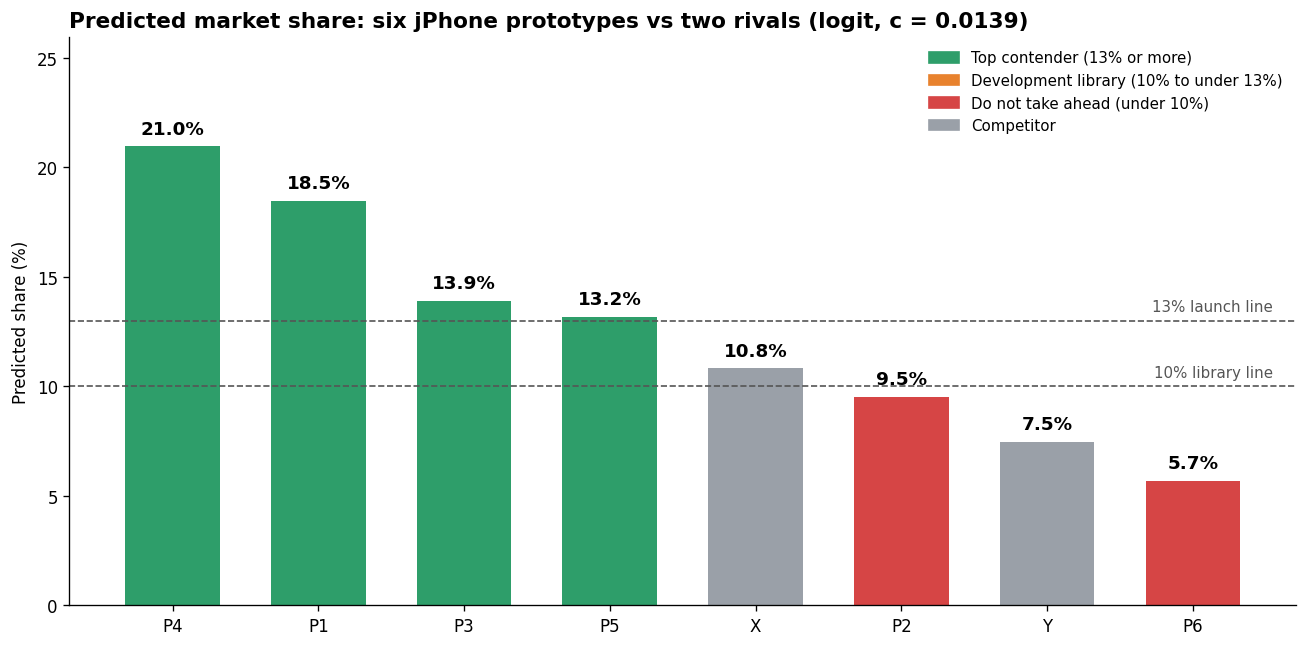

Top contender: P4 (21.0%), P1 (18.5%), P3 (13.9%), P5 (13.2%)
  -> Top contenders to be launched. Take them into 2e (affordable cost) and 2f (pick the winner).

Development library: none
  -> Keep in the development library: use them for future improvements, or to explore new segments.

Do not take ahead: P2 (9.5%), P6 (5.7%)
  -> Should not be taken ahead.

Competition for reference: X (10.8%), Y (7.5%)


In [52]:
# ===== Market share chart: prototypes vs competition =====

# Settings: share thresholds for prototypes
# LAUNCH_MIN is set in the Settings cell at the top
# LIBRARY_MIN is set in the Settings cell at the top
GREEN, ORANGE, RED, GREY = "#2e9e6a", "#e8822e", "#d64545", "#9aa0a8"

share = probs.mean().sort_values(ascending=False)          # predicted share from 2c-1
is_rival = market.set_index("product")["role"].eq("Competitor")

def verdict(product, s):
    if is_rival[product]:
        return "Competitor"
    if s >= LAUNCH_MIN:
        return "Top contender"
    if s >= LIBRARY_MIN:
        return "Development library"
    return "Do not take ahead"

groups = {p: verdict(p, s) for p, s in share.items()}
colour = {"Top contender": GREEN, "Development library": ORANGE, "Do not take ahead": RED, "Competitor": GREY}

# --- chart ---
fig, ax = plt.subplots(figsize=(11, 5.5))
bars = ax.bar([short[p] for p in share.index], share.values * 100,
              color=[colour[groups[p]] for p in share.index], width=0.65)
for b, v in zip(bars, share.values):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.4, f"{v:.1%}",
            ha="center", va="bottom", fontsize=11, fontweight="bold")
for y, lbl in [(LAUNCH_MIN * 100, f"{LAUNCH_MIN:.0%} launch line"), (LIBRARY_MIN * 100, f"{LIBRARY_MIN:.0%} library line")]:
    ax.axhline(y, color="#555", linestyle="--", linewidth=1)
    ax.text(len(share) - 0.45, y + 0.3, lbl, ha="right", va="bottom", fontsize=9, color="#555")

ax.set_title(f"Predicted market share: six jPhone prototypes vs two rivals (logit, c = {C})",
             fontsize=13, fontweight="bold", loc="left")
ax.set_ylabel("Predicted share (%)")
ax.set_ylim(0, share.max() * 100 + 5)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(handles=[Patch(color=GREEN, label="Top contender (13% or more)"),
                   Patch(color=ORANGE, label="Development library (10% to under 13%)"),
                   Patch(color=RED, label="Do not take ahead (under 10%)"),
                   Patch(color=GREY, label="Competitor")],
          loc="upper right", frameon=False, fontsize=9)
plt.tight_layout()
plt.show()

# --- what it means ---
MESSAGE = {
    "Top contender":       "Top contenders to be launched. Take them into 2e (affordable cost) and 2f (pick the winner).",
    "Development library": "Keep in the development library: use them for future improvements, or to explore new segments.",
    "Do not take ahead":   "Should not be taken ahead.",
}
for g, msg in MESSAGE.items():
    members = [f"{short[p]} ({share[p]:.1%})" for p in share.index if groups[p] == g]
    print(f"{g}: {', '.join(members) if members else 'none'}\n  -> {msg}\n")
rivals = [f"{short[p]} ({share[p]:.1%})" for p in share.index if groups[p] == "Competitor"]
print(f"Competition for reference: {', '.join(rivals)}")

**How to read this chart**

- Each bar is one phone's **predicted market share**: the chance each of the 300 customers buys it, averaged across all of them.
- The six jPhone prototypes are coloured by how they perform:
  - **green:** a top contender to launch (13% or more)
  - **orange:** development library (10% to under 13%)
  - **red:** don't take it ahead (under 10%)
- The two rival phones are **grey**, as a benchmark of what is already selling.
- The two dashed lines mark the cut-offs: **13%** for launch and **10%** for the library.
- The bars add up to 100%, because all eight phones share the same customers.

**What it shows**

- **Four prototypes clear the launch line.** P4, the flagship, leads at 21%, followed by P1, the value phone (18.5%), P3, the all-rounder (13.9%), and P5, storage on a budget (13.2%).
- **Four of the six prototypes beat both rivals.** Phone X takes 10.8% and Phone Y 7.5%. Customers prefer most of what the team has built to what is on the shelf today.
- **P2 and P6 fall short.** Both pair a top camera with a **1-day battery**, and battery is a deal-breaker for many customers. P6 (5.7%) also carries the highest price, and sits below every product in the market, rivals included.
- **No prototype lands in the library band.** The six split cleanly: four are worth launching, and two are not.
- **The margins are thin at the edges.** P5 clears the launch line by just 0.2 points, and P2 misses the library line by 0.5 points.

**The takeaway**

The shortlist goes from six to four. P4, P1, P3 and P5 move forward. P2 and P6 stop here, and the lesson they leave is clear: a great camera doesn't make up for a battery that won't last the day.

But share alone doesn't pick the winner. The four contenders sit at three different price points, and each will cost a different amount to build. Step 2e adds the cost each one can afford, and Step 2f weighs share, price and cost headroom together.

> These shares use c = 0.0139. Step 2d tunes c to match today's market; the borderline calls (P5 and P2) can change once it does.

### 2c-2. Non-compensatory approach: lexicographic

The customer looks only at what matters most to them and keeps the products they rate best on it. The next most important attribute comes in **only to break a tie**. Nothing can make up for losing on the top attribute.

We build the customer's shortlist round by round:
1. Rank each customer's attributes by importance.
2. **Round 1:** keep only the products rated best on the most important attribute.
3. **Rounds 2 to 6:** if more than one product is left, move to the next attribute to break the tie.
4. **Final shortlist:** the product left standing is the pick. Anyone still tied after all six attributes picks the higher utility.

#### (i) Rank each customer's attributes, most important first

A lexicographic buyer works down their own list of priorities, so the first job is to sort each customer's six attributes by importance. Customers with different top attributes will be shopping for very different phones.

In [53]:
# ===== 2c-2 (i). Rank each customer's attributes, most important first =====
ORDER = np.argsort(-IMP, axis=1, kind="stable")      # used by the rules below too
ATTR_ORDER = {cid: [ATTR_KEYS[a] for a in ORDER[i]] for i, cid in enumerate(cust.index)}

# Ratings per attribute: customers x products (e.g. RATING["price"].at["C005", "jPhone P1"])
mk = market.set_index("product")
RATING = {a: pd.DataFrame({p: cust[mk.at[p, f"col_{a}"]] for p in products}) for a in ATTR_KEYS}

ranked = pd.DataFrame(
    [[f"{ATTR_NAME[a]} ({cust.at[cid, 'imp_' + a]})" for a in ATTR_ORDER[cid]] for cid in cust.index],
    index=cust.index, columns=["1st", "2nd", "3rd", "4th", "5th", "6th"])
print("Each customer's attributes in order of importance (importance in brackets), first 10 shown:")
display(ranked.head(10))

lead = pd.Series({cid: ATTR_NAME[ATTR_ORDER[cid][0]] for cid in cust.index})
print("Customers by the attribute they look at first:")
display(lead.value_counts().rename("Customers").to_frame().T)

Each customer's attributes in order of importance (importance in brackets), first 10 shown:


,1st,2nd,3rd,4th,5th,6th
customer_id,,,,,,
C001,Memory (39),Price (21),Screen (17),Battery (10),Brand (7),Camera (6)
C002,Screen (32),Memory (20),Price (18),Camera (13),Brand (9),Battery (8)
C003,Battery (34),Price (24),Camera (19),Brand (8),Memory (8),Screen (7)
C004,Camera (37),Battery (21),Brand (13),Memory (13),Price (8),Screen (8)
C005,Price (47),Brand (20),Memory (11),Battery (10),Camera (9),Screen (3)
C006,Battery (50),Memory (16),Price (11),Screen (9),Brand (8),Camera (6)
C007,Price (45),Battery (19),Screen (12),Memory (11),Camera (10),Brand (3)
C008,Memory (26),Battery (24),Brand (17),Camera (13),Price (12),Screen (8)
C009,Brand (30),Camera (19),Memory (19),Screen (18),Price (7),Battery (7)


Customers by the attribute they look at first:


,Price,Camera,Memory,Battery,Screen,Brand
Customers,91,77,55,51,21,5


#### (ii) Round 1: keep only the products rated best on the most important attribute

Each customer looks at their top attribute and keeps every product that shares the best rating on it. If only one product is left, the customer has decided. If several share the top rating, there is a tie, and they move to the next round.

In [54]:
# ===== 2c-2 (ii). Round 1: keep only the products rated best on the most important attribute =====
def best_on(cid, attr, candidates):
    r = RATING[attr].loc[cid, candidates]
    return list(r[r == r.max()].index)

kept = {cid: best_on(cid, ATTR_ORDER[cid][0], products) for cid in cust.index}
decided_round = {cid: 1 for cid, k in kept.items() if len(k) == 1}

round1 = pd.DataFrame({
    "Looks at": [ATTR_NAME[ATTR_ORDER[c][0]] for c in cust.index],
    "Best rating": [RATING[ATTR_ORDER[c][0]].loc[c].max() for c in cust.index],
    "Products kept": [", ".join(short[p] for p in kept[c]) for c in cust.index],
    "How many": [len(kept[c]) for c in cust.index],
}, index=cust.index)
print("Round 1, first 10 customers:")
display(round1.head(10))

print(f"Decided in round 1 (only one product kept): {len(decided_round)} of {len(cust)} customers")
print(f"Still tied, go to their next attribute: {len(cust) - len(decided_round)}")
print("\nHow many products survive round 1:")
display(round1["How many"].value_counts().sort_index().rename_axis("Products kept").rename("Customers").to_frame().T)

Round 1, first 10 customers:


,Looks at,Best rating,Products kept,How many
customer_id,,,,
C001,Memory,7,"P4, P6",2
C002,Screen,6,"P3, P4, Y",3
C003,Battery,7,"P1, P3, P4, P5, X",5
C004,Camera,7,"P2, P4, P6, Y",4
C005,Price,7,"P1, P2, P3, P5, X",5
C006,Battery,7,"P1, P3, P4, P5, X",5
C007,Price,7,"P1, P5",2
C008,Memory,7,"P2, P3, P5, Y",4
C009,Brand,5,"X, Y",2


Decided in round 1 (only one product kept): 4 of 300 customers
Still tied, go to their next attribute: 296

How many products survive round 1:


Products kept,1,2,3,4,5,6,7,8
Customers,4,133,25,74,54,4,5,1


#### (iii) Rounds 2 to 6: the next attribute only breaks ties

Customers who are still tied look at their next most important attribute, but **only among the products they kept**. Everything already knocked out stays out, however good it is on this attribute. This repeats until one product is left, or all six attributes are used.

The table shows how many customers settle in each round. The walk-through follows the example customer.

In [55]:
# ===== 2c-2 (iii). Rounds 2 to 6: the next attribute only breaks ties =====
rounds = [{"Round": 1, "Attribute used": "1st", "Decided this round": len(decided_round),
           "Still tied": len(cust) - len(decided_round)}]
for rnd in range(2, len(ATTR_KEYS) + 1):
    for cid in cust.index:
        if len(kept[cid]) > 1:
            kept[cid] = best_on(cid, ATTR_ORDER[cid][rnd - 1], kept[cid])
            if len(kept[cid]) == 1:
                decided_round[cid] = rnd
    n_now = sum(1 for r in decided_round.values() if r == rnd)
    rounds.append({"Round": rnd, "Attribute used": ["1st", "2nd", "3rd", "4th", "5th", "6th"][rnd - 1],
                   "Decided this round": n_now, "Still tied": sum(len(k) > 1 for k in kept.values())})
print("How the ties are broken, round by round:")
display(pd.DataFrame(rounds).set_index("Round"))

# Walk-through for the example customer
print(f"\nExample, customer {example_id}:")
cand = products
for rnd, a in enumerate(ATTR_ORDER[example_id], start=1):
    ratings = ", ".join(f"{short[p]}={RATING[a].at[example_id, p]}" for p in cand)
    cand = best_on(example_id, a, cand)
    print(f"  Round {rnd}: {ATTR_NAME[a]:<8} ratings {ratings}  ->  keeps {', '.join(short[p] for p in cand)}")
    if len(cand) == 1:
        break

How the ties are broken, round by round:


,Attribute used,Decided this round,Still tied
Round,,,
1,1st,4,296
2,2nd,146,150
3,3rd,103,47
4,4th,35,12
5,5th,11,1
6,6th,1,0



Example, customer C005:
  Round 1: Price    ratings P1=7, P2=7, P3=7, P4=2, P5=7, P6=2, X=7, Y=2  ->  keeps P1, P2, P3, P5, X
  Round 2: Brand    ratings P1=3, P2=3, P3=3, P5=3, X=6  ->  keeps X


#### (iv) Final shortlist and choice

Each customer is left with a final shortlist, usually a single product, which is their pick. If anyone is still tied after all six attributes, the higher utility from 2c-1 breaks the tie.

The cell compares each customer's lexicographic pick with their compensatory pick, and shows how first choices across the market change when customers stop trading off.

In [56]:
# ===== 2c-2 (iv). Final shortlist and choice =====
# Anyone still tied after all six attributes picks the higher utility among what is left.
allowed = pd.DataFrame(False, index=cust.index, columns=products)
for cid, k in kept.items():
    allowed.loc[cid, k] = True
PICKS["Lexicographic"] = pick_best(allowed)

final = pd.DataFrame({
    "Final shortlist": [", ".join(short[p] for p in kept[c]) for c in cust.index],
    "Decided in round": [decided_round.get(c, "tie: utility") for c in cust.index],
    "Lexicographic pick": PICKS["Lexicographic"].map(short),
    "Compensatory pick": PICKS["Compensatory"].map(short),
}, index=cust.index)
print("Final shortlist and pick, first 10 customers:")
display(final.head(10))

changed = (PICKS["Lexicographic"] != PICKS["Compensatory"]).sum()
print(f"Customers still tied after all six attributes (utility breaks the tie): "
      f"{sum(len(k) > 1 for k in kept.values())}")

Final shortlist and pick, first 10 customers:


,Final shortlist,Decided in round,Lexicographic pick,Compensatory pick
customer_id,,,,
C001,P4,3,P4,P4
C002,P3,3,P3,P3
C003,P1,3,P1,P1
C004,P4,2,P4,P4
C005,X,2,X,X
C006,P5,3,P5,P3
C007,P1,3,P1,P1
C008,P3,4,P3,P3
C009,Y,2,Y,P4


Customers still tied after all six attributes (utility breaks the tie): 0


In [57]:
print(f"Customers whose pick differs from the compensatory pick: {changed} of {len(cust)}\n")

comp = first_choice(PICKS["Compensatory"], "Compensatory").iloc[:, :1].join(
       first_choice(PICKS["Lexicographic"], "Lexicographic"))
comp["Change vs compensatory"] = comp["Lexicographic"] - comp["Compensatory"]
comp.index = [short.get(p, p) for p in comp.index]

Customers whose pick differs from the compensatory pick: 75 of 300



In [58]:
# ===== Styled table: compensatory vs lexicographic first choices =====

INK, MUTED, WHITE, LINE = "#1f2328", "#6b7078", "#ffffff", "#e6e4df"
BLUE_T, BLUE_TXT, BLUE_BAR = "#eaf1fb", "#1f5fae", "#d3e3f7"   # compensatory
ORNG_T, ORNG_TXT, ORNG_BAR = "#fcf1e6", "#a8561a", "#f6dcc4"   # lexicographic
UP_BG, UP_TXT = "#eef7f1", "#2f7d4f"
DOWN_BG, DOWN_TXT = "#fbefef", "#b04a4a"
RIVAL_BG = "#f6f5f2"
CHG = "Change vs compensatory"

n = len(cust)
t = comp.drop(index="Buys nothing", errors="ignore").copy()
t = t[["Compensatory", "Lexicographic", CHG]]
t.insert(1, "Compensatory share", t["Compensatory"] / n)
t.insert(3, "Lexicographic share", t["Lexicographic"] / n)

rivals = [short[p] for p in products if mk.at[p, "role"] == "Competitor"]
t = t.rename(index={r: f"Phone {r}" for r in rivals})
t = t.rename_axis("Product").reset_index()
rivals = [f"Phone {r}" for r in rivals]
vmax = t[["Compensatory", "Lexicographic"]].max().max()


def base(row):
    is_rival = row["Product"] in rivals
    bg = RIVAL_BG if is_rival else WHITE
    italic = "font-style:italic; " if is_rival else ""
    return [f"{italic}background-color:{bg}; color:{INK}"] * len(row)


def bar(colour):
    # solid bar on a light base (nothing transparent)
    def f(col):
        out = []
        for v, p in zip(col, t["Product"]):
            pct = v / vmax * 100
            rest = RIVAL_BG if p in rivals else WHITE
            out.append(f"background: linear-gradient(90deg, {colour} {pct:.0f}%, "
                       f"{rest} {pct:.0f}%); color:{INK}")
        return out
    return f


def change_cell(v):
    if v > 0:
        return f"background-color:{UP_BG}; color:{UP_TXT}; font-weight:700"
    if v < 0:
        return f"background-color:{DOWN_BG}; color:{DOWN_TXT}; font-weight:700"
    return f"background-color:{WHITE}; color:{MUTED}"


def arrow(v):
    if v > 0:
        return f"▲ +{v}"
    if v < 0:
        return f"▼ {v}"
    return "–"


TABLE_STYLES = [
    {"selector": "",
     "props": f"border-collapse:collapse; background-color:{WHITE}; "
              "font-family:Arial, sans-serif; border:1px solid #d9d6cf"},
    {"selector": "caption",
     "props": f"caption-side:top; font-size:15px; font-weight:700; color:{INK}; "
              f"background-color:{WHITE}; text-align:left; padding:10px 14px"},
    {"selector": "th",
     "props": f"color:{INK}; background-color:#f1f0ec; font-weight:700; "
              "text-align:center; padding:8px 14px; border-bottom:2px solid #d9d6cf"},
    {"selector": "th.col1, th.col2",
     "props": f"background-color:{BLUE_T}; color:{BLUE_TXT}"},
    {"selector": "th.col3, th.col4",
     "props": f"background-color:{ORNG_T}; color:{ORNG_TXT}"},
    {"selector": "td",
     "props": f"text-align:center; padding:6px 14px; font-size:14px; "
              f"border-bottom:1px solid {LINE}"},
    {"selector": "td.col0",
     "props": "font-weight:700; text-align:left"},
]

FORMATS = {
    "Compensatory": "{:d}",
    "Lexicographic": "{:d}",
    "Compensatory share": "{:.0%}",
    "Lexicographic share": "{:.0%}",
    CHG: arrow,
}

styled = (
    t.style
    .hide(axis="index")
    .apply(base, axis=1)
    .apply(bar(BLUE_BAR), subset=["Compensatory"])
    .apply(bar(ORNG_BAR), subset=["Lexicographic"])
    .map(change_cell, subset=[CHG])
    .format(FORMATS)
    .set_caption(f"First choice: trade off vs decide lexicographically "
                 f"(customers out of {n})")
    .set_table_styles(TABLE_STYLES)
)
display(styled)

ch = t.set_index("Product")[CHG]
print(f"Biggest gain: {ch.idxmax()} ({ch.max():+d})   "
      f"Biggest loss: {ch.idxmin()} ({ch.min():+d})   Rival phones in italics.")

Product,Compensatory,Compensatory share,Lexicographic,Lexicographic share,Change vs compensatory
P1,87,29%,78,26%,▼ -9
P2,20,7%,29,10%,▲ +9
P3,18,6%,11,4%,▼ -7
P4,129,43%,115,38%,▼ -14
P5,28,9%,43,14%,▲ +15
P6,0,0%,2,1%,▲ +2
Phone X,14,5%,12,4%,▼ -2
Phone Y,4,1%,10,3%,▲ +6


Biggest gain: P5 (+15)   Biggest loss: P4 (-14)   Rival phones in italics.


**How to read this table**

- Each row is a phone; the two rival phones are shaded grey.
- **Compensatory** (blue) is how many of the 300 customers pick each phone when they trade off, weighing every attribute and adding it up.
- **Lexicographic** (orange) is how many pick it when they decide on their **most important attribute first**, and use the next one only to break a tie.
- The bars inside the cells show the size of each count; both columns use the same scale.
- **Lexicographic share** is the orange count as a share of all 300 customers.
- **Change vs compensatory** shows who gains (green ▲) and who loses (red ▼) when customers stop adding things up and start ranking them.

**What it shows**

- **A quarter of the market changes its mind.** 75 of 300 customers pick a different phone when they decide by priority rather than by trade-off.
- **Specialists gain.** P5 (storage on a budget) gains the most, +15. P2 (camera) gains +9, and Phone Y gains +6. Each is the best at one thing a customer cares most about.
- **All-rounders lose.** P4 (flagship) loses the most, −14. P1 (value) loses 9 and P3 (all-rounder) loses 7. Their strength is being good across the board, and a lexicographic buyer never adds that up.
- **P4 still leads, at 38% of first choices.** It loses ground, but its lead is wide enough to hold even when customers stop trading off.
- **P6 barely registers.** It goes from 0 to 2 customers. Being best on one thing isn't enough when it fails on the things that matter more.

**The takeaway**

How customers decide changes who wins. When buyers trade off, being good at everything pays. When they rank, being **the best at the one thing they care about most** pays, and an all-rounder can lose to a specialist it beats on every average.

So before you pick a winner, know how your customers decide. A product that wins under both rules, as P4 does here, is a safer launch. A product that only wins under one rule needs a clear answer to who it's for.

### 2c-3. Non-compensatory approach: elimination by aspects

The customer sets a bar on each attribute and works down from the most important. Products that miss a bar are knocked out, until one is left. Unlike lexicographic, the customer doesn't hunt for the *best* product on each attribute: they just want it to be *good enough*.

We build each customer's shortlist round by round:
1. **Set the bar:** a level clears it if the customer rates it 5 or more out of 7.
2. **Round 1:** knock out every product below the bar on the most important attribute.
3. **Rounds 2 to 6:** apply the next bar, only among the products still standing. A bar that would knock out every product left is skipped, because the customer won't walk away with nothing.
4. **Final shortlist:** the product left standing is the pick. If several clear every bar, the higher utility picks between them.

#### (i) Set the bar: which products clear it on each attribute

For the example customer, the table shows every product's rating on each attribute, with the most important attribute at the top. ✓ means the level clears the bar, and ✗ means it misses.

The summary shows how many of the six attributes each product clears for the average customer. A product that clears few bars is likely to be knocked out early.

In [59]:
# ===== 2c-3 (i). Set the bar: which products clear it on each attribute =====
# EBA_BAR is set in the Settings cell at the top

# True where the customer rates the product's level at or above the bar
CLEARS = {a: RATING[a] >= EBA_BAR for a in ATTR_KEYS}

# Example customer: every attribute (most important first) x every product
ex_rows = []
for a in ATTR_ORDER[example_id]:
    row = {"Attribute": f"{ATTR_NAME[a]} ({cust.at[example_id, 'imp_' + a]})"}
    for p in products:
        r = RATING[a].at[example_id, p]
        row[short[p]] = f"{r} ✓" if r >= EBA_BAR else f"{r} ✗"
    ex_rows.append(row)
print(f"Example, customer {example_id}: rating of each product's level "
      f"(✓ clears the bar of {EBA_BAR}, ✗ misses it)")
display(pd.DataFrame(ex_rows).set_index("Attribute"))

# Across all customers: on how many of the six attributes does each product clear the bar?
n_clear = sum(CLEARS[a].astype(int) for a in ATTR_KEYS)
summary = pd.DataFrame({
    "Avg attributes cleared (of 6)": n_clear.mean().round(1),
    "Clears all six": (n_clear == 6).sum(),
}).rename(index=short).T
print("\nHow often each product clears the bar, across all customers:")
display(summary.style.format("{:g}"))

Example, customer C005: rating of each product's level (✓ clears the bar of 5, ✗ misses it)


,P1,P2,P3,P4,P5,P6,X,Y
Attribute,,,,,,,,
Price (47),7 ✓,7 ✓,7 ✓,2 ✗,7 ✓,2 ✗,7 ✓,2 ✗
Brand (20),3 ✗,3 ✗,3 ✗,3 ✗,3 ✗,3 ✗,6 ✓,5 ✓
Memory (11),4 ✗,5 ✓,5 ✓,5 ✓,5 ✓,5 ✓,4 ✗,5 ✓
Battery (10),6 ✓,2 ✗,6 ✓,6 ✓,6 ✓,2 ✗,6 ✓,2 ✗
Camera (9),3 ✗,6 ✓,3 ✗,6 ✓,2 ✗,6 ✓,3 ✗,6 ✓
Screen (3),5 ✓,5 ✓,5 ✓,5 ✓,4 ✗,4 ✗,5 ✓,5 ✓



How often each product clears the bar, across all customers:


,P1,P2,P3,P4,P5,P6,X,Y
Avg attributes cleared (of 6),3.5,2.9,3.2,3.6,3.1,2.4,3.4,2.6
Clears all six,1,0,4,0,0,0,4,0


#### (ii) Round 1: knock out products below the bar on the most important attribute

Each customer applies the bar on their top attribute. Every product below it is out, however good the rest is.

In [60]:
# ===== 2c-3 (ii). Round 1: knock out products below the bar on the top attribute =====
eba_kept, eba_round, eba_skipped = {}, {}, {}

def apply_bar(cid, attr, candidates):
    """Products that clear the bar; if none would, the bar is skipped and all stay."""
    keep = [p for p in candidates if CLEARS[attr].at[cid, p]]
    return (keep, False) if keep else (list(candidates), True)

for cid in cust.index:
    keep, skipped = apply_bar(cid, ATTR_ORDER[cid][0], products)
    eba_kept[cid] = keep
    eba_skipped[cid] = int(skipped)
    if len(keep) == 1:
        eba_round[cid] = 1

r1 = pd.DataFrame({
    "Looks at": [ATTR_NAME[ATTR_ORDER[c][0]] for c in cust.index],
    "Knocked out": [", ".join(short[p] for p in products if p not in eba_kept[c])
                    or "none" for c in cust.index],
    "Left": [", ".join(short[p] for p in eba_kept[c]) for c in cust.index],
    "How many": [len(eba_kept[c]) for c in cust.index],
}, index=cust.index)
print("Round 1, first 10 customers:")
display(r1.head(10))

avg_out = (len(products) - r1["How many"]).mean()
print(f"Knocked out per customer in round 1, on average: {avg_out:.1f} of {len(products)}")
print(f"Decided in round 1 (one product left): {len(eba_round)} of {len(cust)}")
print(f"Bar skipped (every product missed it): {sum(eba_skipped.values())}")
print(f"More than one left, go to the next bar: {(r1['How many'] > 1).sum()}")

Round 1, first 10 customers:


,Looks at,Knocked out,Left,How many
customer_id,,,,
C001,Memory,"P1, X","P2, P3, P4, P5, P6, Y",6
C002,Screen,"P1, P2, P5, P6, X","P3, P4, Y",3
C003,Battery,"P2, P6, Y","P1, P3, P4, P5, X",5
C004,Camera,P5,"P1, P2, P3, P4, P6, X, Y",7
C005,Price,"P4, P6, Y","P1, P2, P3, P5, X",5
C006,Battery,"P2, P6, Y","P1, P3, P4, P5, X",5
C007,Price,"P4, P6, Y","P1, P2, P3, P5, X",5
C008,Memory,"P1, P4, P6, X","P2, P3, P5, Y",4
C009,Brand,"P1, P2, P3, P4, P5, P6","X, Y",2


Knocked out per customer in round 1, on average: 3.6 of 8
Decided in round 1 (one product left): 1 of 300
Bar skipped (every product missed it): 0
More than one left, go to the next bar: 299


#### (iii) Rounds 2 to 6: the next bar, among the products still standing

Customers with more than one product left apply their next bar. A knocked-out product never comes back. If a bar would knock out every product left, the customer skips it rather than walk away.

In [61]:
# ===== 2c-3 (iii). Rounds 2 to 6: the next bar, among the products still standing =====
ORD = ["1st", "2nd", "3rd", "4th", "5th", "6th"]
eba_rounds = [{"Round": 1, "Bar on": ORD[0], "Decided this round": len(eba_round),
               "Bars skipped": sum(eba_skipped.values()),
               "Still more than one": sum(len(k) > 1 for k in eba_kept.values())}]

for rnd in range(2, len(ATTR_KEYS) + 1):
    skipped_now = 0
    for cid in cust.index:
        if len(eba_kept[cid]) > 1:
            keep, skipped = apply_bar(cid, ATTR_ORDER[cid][rnd - 1], eba_kept[cid])
            eba_kept[cid] = keep
            skipped_now += int(skipped)
            if len(keep) == 1:
                eba_round[cid] = rnd
    eba_rounds.append({
        "Round": rnd, "Bar on": ORD[rnd - 1],
        "Decided this round": sum(1 for r in eba_round.values() if r == rnd),
        "Bars skipped": skipped_now,
        "Still more than one": sum(len(k) > 1 for k in eba_kept.values())})

print("How the products are knocked out, round by round:")
display(pd.DataFrame(eba_rounds).set_index("Round"))

# Walk-through for the example customer
print(f"\nExample, customer {example_id}:")
cand = products
for rnd, a in enumerate(ATTR_ORDER[example_id], start=1):
    new, skipped = apply_bar(example_id, a, cand)
    out = [short[p] for p in cand if p not in new]
    note = "bar skipped (every product left misses it)" if skipped else \
           f"knocks out {', '.join(out) if out else 'nothing'}"
    cand = new
    print(f"  Round {rnd}: {ATTR_NAME[a]:<8} {note}  ->  "
          f"left: {', '.join(short[p] for p in cand)}")
    if len(cand) == 1:
        break

How the products are knocked out, round by round:


,Bar on,Decided this round,Bars skipped,Still more than one
Round,,,,
1,1st,1,0,299
2,2nd,93,47,206
3,3rd,73,46,133
4,4th,43,50,90
5,5th,32,32,58
6,6th,22,20,36



Example, customer C005:
  Round 1: Price    knocks out P4, P6, Y  ->  left: P1, P2, P3, P5, X
  Round 2: Brand    knocks out P1, P2, P3, P5  ->  left: X


#### (iv) Final shortlist and choice

The product left standing is the pick. If several products clear every bar, the customer takes the one with the higher utility from 2c-1.

In [62]:
# ===== 2c-3 (iv). Final shortlist and choice =====
# If several products clear every bar, the higher utility from 2c-1 picks between them.
allowed = pd.DataFrame(False, index=cust.index, columns=products)
for cid, k in eba_kept.items():
    allowed.loc[cid, k] = True
PICKS["Elimination by aspects"] = pick_best(allowed)

final = pd.DataFrame({
    "Final shortlist": [", ".join(short[p] for p in eba_kept[c]) for c in cust.index],
    "Decided in round": [eba_round.get(c, "tie: utility") for c in cust.index],
    "EBA pick": PICKS["Elimination by aspects"].map(short),
    "Compensatory pick": PICKS["Compensatory"].map(short),
}, index=cust.index)
print("Final shortlist and pick, first 10 customers:")
display(final.head(10))

n_tie = sum(len(k) > 1 for k in eba_kept.values())
n_changed = (PICKS["Elimination by aspects"] != PICKS["Compensatory"]).sum()
print(f"Several products cleared every bar (utility picked): {n_tie}")
print(f"Customers whose pick differs from the compensatory pick: "
      f"{n_changed} of {len(cust)}")

Final shortlist and pick, first 10 customers:


,Final shortlist,Decided in round,EBA pick,Compensatory pick
customer_id,,,,
C001,P5,2,P5,P4
C002,P3,3,P3,P3
C003,P1,3,P1,P1
C004,X,3,X,P4
C005,X,2,X,X
C006,P5,3,P5,P3
C007,X,6,X,P1
C008,"P3, P5",tie: utility,P3,P3
C009,Y,3,Y,P4


Several products cleared every bar (utility picked): 36
Customers whose pick differs from the compensatory pick: 116 of 300


#### (v) Elimination by aspects vs the compensatory approach

In [63]:
# ===== Comparison table: any rule vs compensatory (works in light and dark themes) =====
INK, MUTED, WHITE, LINE = "#1f2328", "#6b7078", "#ffffff", "#e6e4df"
BLUE_T, BLUE_TXT, BLUE_BAR = "#eaf1fb", "#1f5fae", "#d3e3f7"   # compensatory
ORNG_T, ORNG_TXT, ORNG_BAR = "#fcf1e6", "#a8561a", "#f6dcc4"   # the other rule
UP_BG, UP_TXT = "#eef7f1", "#2f7d4f"
DOWN_BG, DOWN_TXT = "#fbefef", "#b04a4a"
RIVAL_BG = "#f6f5f2"


def compare_with_compensatory(rule, caption_rule):
    """Styled table: first choices under `rule` vs the compensatory approach."""
    n = len(cust)
    chg = "Change vs compensatory"
    order = products
    a = PICKS["Compensatory"].value_counts().reindex(order).fillna(0).astype(int)
    b = PICKS[rule].value_counts().reindex(order).fillna(0).astype(int)
    t = pd.DataFrame({"Compensatory": a, "Compensatory share": a / n,
                      rule: b, f"{rule} share": b / n, chg: b - a})

    rivals = [p for p in products if mk.at[p, "role"] == "Competitor"]
    names = {p: (p if p in rivals else short[p]) for p in products}
    t = t.rename(index=names).rename_axis("Product").reset_index()
    rivals = [names[p] for p in rivals]
    vmax = t[["Compensatory", rule]].max().max()

    def base(row):
        is_rival = row["Product"] in rivals
        bg = RIVAL_BG if is_rival else WHITE
        italic = "font-style:italic; " if is_rival else ""
        return [f"{italic}background-color:{bg}; color:{INK}"] * len(row)

    def bar(colour):
        def f(col):
            out = []
            for v, p in zip(col, t["Product"]):
                pct = v / vmax * 100
                rest = RIVAL_BG if p in rivals else WHITE
                out.append(f"background: linear-gradient(90deg, {colour} {pct:.0f}%, "
                           f"{rest} {pct:.0f}%); color:{INK}")
            return out
        return f

    def change_cell(v):
        if v > 0:
            return f"background-color:{UP_BG}; color:{UP_TXT}; font-weight:700"
        if v < 0:
            return f"background-color:{DOWN_BG}; color:{DOWN_TXT}; font-weight:700"
        return f"background-color:{WHITE}; color:{MUTED}"

    def arrow(v):
        if v > 0:
            return f"▲ +{v}"
        if v < 0:
            return f"▼ {v}"
        return "–"

    styles = [
        {"selector": "",
         "props": f"border-collapse:collapse; background-color:{WHITE}; "
                  "font-family:Arial, sans-serif; border:1px solid #d9d6cf"},
        {"selector": "caption",
         "props": f"caption-side:top; font-size:15px; font-weight:700; color:{INK}; "
                  f"background-color:{WHITE}; text-align:left; padding:10px 14px"},
        {"selector": "th",
         "props": f"color:{INK}; background-color:#f1f0ec; font-weight:700; "
                  "text-align:center; padding:8px 14px; border-bottom:2px solid #d9d6cf"},
        {"selector": "th.col1, th.col2",
         "props": f"background-color:{BLUE_T}; color:{BLUE_TXT}"},
        {"selector": "th.col3, th.col4",
         "props": f"background-color:{ORNG_T}; color:{ORNG_TXT}"},
        {"selector": "td",
         "props": f"text-align:center; padding:6px 14px; font-size:14px; "
                  f"border-bottom:1px solid {LINE}"},
        {"selector": "td.col0",
         "props": "font-weight:700; text-align:left"},
    ]
    formats = {"Compensatory": "{:d}", rule: "{:d}",
               "Compensatory share": "{:.0%}", f"{rule} share": "{:.0%}", chg: arrow}

    styled = (
        t.style
        .hide(axis="index")
        .apply(base, axis=1)
        .apply(bar(BLUE_BAR), subset=["Compensatory"])
        .apply(bar(ORNG_BAR), subset=[rule])
        .map(change_cell, subset=[chg])
        .format(formats)
        .set_caption(f"First choice: trade off vs {caption_rule} (customers out of {n})")
        .set_table_styles(styles)
    )
    display(styled)

    ch = t.set_index("Product")[chg]
    print(f"Biggest gain: {ch.idxmax()} ({ch.max():+d})   "
          f"Biggest loss: {ch.idxmin()} ({ch.min():+d})   Rival phones in italics.")


compare_with_compensatory("Elimination by aspects", "eliminate by aspects")

Product,Compensatory,Compensatory share,Elimination by aspects,Elimination by aspects share,Change vs compensatory
P1,87,29%,64,21%,▼ -23
P2,20,7%,13,4%,▼ -7
P3,18,6%,33,11%,▲ +15
P4,129,43%,101,34%,▼ -28
P5,28,9%,46,15%,▲ +18
P6,0,0%,3,1%,▲ +3
Phone X,14,5%,28,9%,▲ +14
Phone Y,4,1%,12,4%,▲ +8


Biggest gain: P5 (+18)   Biggest loss: P4 (-28)   Rival phones in italics.


**How to read this table**

- Each row is a phone; the two rival phones are in italics on a grey background.
- **Compensatory** (blue) is how many of the 300 customers pick each phone when they trade off, weighing every attribute and adding it up.
- **Elimination by aspects** (orange) is how many pick it when they work down their priorities and knock out any phone that isn't **good enough**: rated below 5 out of 7 on that attribute.
- The bars inside the cells show the size of each count, on the same scale.
- **Compensatory share** and **Elimination by aspects share** are each count as a share of all 300 customers.
- **Change vs compensatory** shows who gains (green ▲) and who loses (red ▼) when customers screen out the weak instead of adding up the strong.

**What it shows**

- **This rule shakes up the market the most.** 116 of 300 customers pick a different phone, compared with 75 under the lexicographic rule. A single "not good enough" knocks a phone out, however strong it is elsewhere.
- **The leaders take the biggest hits.** P4, the flagship, loses 28 customers because its ₹30k price misses the bar for many buyers. P1, the value phone, loses 23 because its 128 GB memory falls short.
- **The rivals double.** Phone X goes from 14 to 28 customers, and Phone Y from 4 to 12. When jPhones are knocked out on brand or price, the rivals are what's left standing.
- **The phones with no weak spot gain.** P5 (+18) and P3 (+15) rarely miss a bar, so they survive when others are eliminated.
- **P4 still leads, but with a third of the market (34%), down from 43%.**

**The takeaway**

When customers eliminate, **a weakness costs more than a strength earns.** A phone doesn't win by being brilliant at one thing. It wins by not being bad at anything the customer cares about.

That changes the brief for product teams: find the attribute where your product falls short, and fix it before you add another strength. And watch the rivals. Every jPhone knocked out on a single weak spot hands a customer to the competition.

### 2c-4. Non-compensatory approach: conjunctive (must pass every test)

A phone stays on the list only if it clears **every** minimum the customer sets. One miss, and it's out, however good the rest is.

This is the one rule the data records directly. The 108 customers who screen first each gave three deal-breakers: a **maximum price**, a **minimum battery life** and a **minimum memory**. The other 192 trade off and have no deal-breakers, so their pick doesn't change.

We build each screener's shortlist step by step:
1. See who screens, and what they insist on.
2. Test every product against every deal-breaker.
3. Each screener's shortlist: the products that pass every test.
4. Final choice: the highest utility among the shortlist. This is the blog's **consider, then choose**, and the model carried into Steps 2d and 2e.

#### (i) The deal-breakers: who screens, and what they insist on

How many customers screen first, and how strict they are on price, battery and memory.

In [64]:
# ===== 2c-4 (i). The deal-breakers: who screens, and what they insist on =====
# NO_PRODUCT_LEFT is set in the Settings cell at the top
BATTERY_DAYS = {"1 day": 1, "2 days": 2}

def gb(s):
    return int(str(s).split()[0])

screeners = cust["decision_rule"].eq("Screen first")
sc = cust[screeners]
print(f"Customers who screen first: {screeners.sum()} of {len(cust)} "
      f"({screeners.mean():.0%}). The other {(~screeners).sum()} trade off and have "
      f"no deal-breakers.\n")

tests = {
    "Price at most": sc["dealbreaker_max_price"].map(lambda v: f"₹{v / 1000:.0f}k"),
    "Battery at least": sc["dealbreaker_min_battery"],
    "Memory at least": sc["dealbreaker_min_memory"],
}
for name, col in tests.items():
    counts = col.value_counts().sort_index()
    print(f"{name}:")
    display(counts.rename_axis(None).rename("Screeners").to_frame().T)

print(f"Example, customer {example_id}: price at most "
      f"₹{cust.at[example_id, 'dealbreaker_max_price']:,.0f}, battery at least "
      f"{cust.at[example_id, 'dealbreaker_min_battery']}, memory at least "
      f"{cust.at[example_id, 'dealbreaker_min_memory']}")

Customers who screen first: 108 of 300 (36%). The other 192 trade off and have no deal-breakers.

Price at most:


,₹25k,₹30k
Screeners,61,47


Battery at least:


,1 day,2 days
Screeners,46,62


Memory at least:


,128 GB,256 GB
Screeners,58,50


Example, customer C005: price at most ₹30,000, battery at least 2 days, memory at least 128 GB


#### (ii) Test every product against every deal-breaker

For the example customer: which tests each product passes (✓) or fails (✗). Across all screeners: how many rule each product out, and which test it fails.

In [65]:
# ===== 2c-4 (ii). Test every product against every deal-breaker =====
FAIL_PRICE, FAIL_BATT, FAIL_MEM = {}, {}, {}
for _, prod in market.iterrows():
    p = prod["product"]
    FAIL_PRICE[p] = (prod["price"] > cust["dealbreaker_max_price"]) & screeners
    min_batt = cust["dealbreaker_min_battery"].map(BATTERY_DAYS)
    FAIL_BATT[p] = (BATTERY_DAYS[prod["battery"]] < min_batt) & screeners
    min_mem = cust["dealbreaker_min_memory"].map(gb, na_action="ignore")
    FAIL_MEM[p] = (gb(prod["memory"]) < min_mem) & screeners

FAILS = pd.DataFrame({p: FAIL_PRICE[p] | FAIL_BATT[p] | FAIL_MEM[p] for p in products})
PASSES = ~FAILS

# Example customer: product x test
ex = pd.DataFrame({
    "Price": [("✗" if FAIL_PRICE[p][example_id] else "✓") for p in products],
    "Battery": [("✗" if FAIL_BATT[p][example_id] else "✓") for p in products],
    "Memory": [("✗" if FAIL_MEM[p][example_id] else "✓") for p in products],
}, index=[short[p] for p in products])
ex["Passes every test"] = PASSES.loc[example_id].map({True: "Yes", False: "No"}).values
print(f"Example, customer {example_id} (✓ passes, ✗ fails):")
display(ex.T)

# All screeners: how many rule each product out, and why
why = pd.DataFrame({
    "Ruled out": FAILS[screeners].sum(),
    "Price too high": pd.Series({p: FAIL_PRICE[p].sum() for p in products}),
    "Battery too short": pd.Series({p: FAIL_BATT[p].sum() for p in products}),
    "Memory too small": pd.Series({p: FAIL_MEM[p].sum() for p in products}),
}).rename(index=short)
why["Ruled out (%)"] = (why["Ruled out"] / screeners.sum() * 100).round(0).astype(int)
print(f"\nHow many of the {screeners.sum()} screeners rule each product out, and why "
      f"(a product can fail more than one test):")
display(why)

Example, customer C005 (✓ passes, ✗ fails):


,P1,P2,P3,P4,P5,P6,X,Y
Price,✓,✓,✓,✓,✓,✓,✓,✓
Battery,✓,✗,✓,✓,✓,✗,✓,✗
Memory,✓,✓,✓,✓,✓,✓,✓,✓
Passes every test,Yes,No,Yes,Yes,Yes,No,Yes,No



How many of the 108 screeners rule each product out, and why (a product can fail more than one test):


,Ruled out,Price too high,Battery too short,Memory too small,Ruled out (%)
P1,50,0,0,50,46
P2,62,0,62,0,57
P3,0,0,0,0,0
P4,61,61,0,0,56
P5,0,0,0,0,0
P6,88,61,62,0,81
X,50,0,0,50,46
Y,88,61,62,0,81


#### (iii) Each screener's shortlist: the products that pass every test

What is left once the deal-breakers are applied. A screener only ever chooses from this list.

In [66]:
# ===== 2c-4 (iii). Each screener's shortlist: the products that pass every test =====
n_pass = PASSES[screeners].sum(axis=1)

short_tbl = pd.DataFrame({
    "Passes every test": [", ".join(short[p] for p in products if PASSES.at[c, p]) or "none"
                          for c in sc.index],
    "How many": n_pass.values,
}, index=sc.index)
print("Shortlist after the deal-breakers, first 10 screeners:")
display(short_tbl.head(10))

print("How many products survive for each screener:")
display(n_pass.value_counts().sort_index().rename_axis("Products left")
        .rename("Screeners").to_frame().T)
print(f"Products knocked out per screener, on average: "
      f"{len(products) - n_pass.mean():.1f} of {len(products)}")
print(f"Screeners left with no acceptable product: {(n_pass == 0).sum()}")

Shortlist after the deal-breakers, first 10 screeners:


,Passes every test,How many
customer_id,,
C005,"P1, P3, P4, P5, X",5
C010,"P1, P3, P4, P5, X",5
C013,"P1, P2, P3, P4, P5, P6, X, Y",8
C014,"P3, P5",2
C017,"P2, P3, P4, P5, P6, Y",6
C018,"P1, P3, P5, X",4
C023,"P2, P3, P5",3
C026,"P2, P3, P4, P5, P6, Y",6
C029,"P1, P3, P4, P5, X",5


How many products survive for each screener:


Products left,2,3,4,5,6,8
Screeners,20,22,15,31,8,12


Products knocked out per screener, on average: 3.7 of 8
Screeners left with no acceptable product: 0


#### (iv) Final choice: the highest utility among what passed

Each screener picks the product with the highest utility from their shortlist. Customers who trade off keep their compensatory pick.

In [67]:
# ===== 2c-4 (iv). Final choice: the highest utility among what passed =====
# Screeners choose among their shortlist; customers who trade off are unaffected.
pick = pick_best(PASSES)
if NO_PRODUCT_LEFT == "best":
    pick = pick.replace("Buys nothing", np.nan).fillna(PICKS["Compensatory"])
PICKS["Conjunctive"] = pick

final = pd.DataFrame({
    "Shortlist": short_tbl["Passes every test"],
    "Conjunctive pick": PICKS["Conjunctive"][sc.index].map(lambda p: short.get(p, p)),
    "Compensatory pick": PICKS["Compensatory"][sc.index].map(short),
}, index=sc.index)
final["Changed?"] = (final["Conjunctive pick"] != final["Compensatory pick"]) \
    .map({True: "Yes", False: ""})
print("Final pick, first 10 screeners:")
display(final.head(10))

n_changed = (PICKS["Conjunctive"] != PICKS["Compensatory"]).sum()
print(f"Screeners whose pick changes once the deal-breakers apply: "
      f"{n_changed} of {screeners.sum()}")
print(f"Customers who trade off (unchanged): {(~screeners).sum()}")

Final pick, first 10 screeners:


,Shortlist,Conjunctive pick,Compensatory pick,Changed?
customer_id,,,,
C005,"P1, P3, P4, P5, X",X,X,
C010,"P1, P3, P4, P5, X",P1,P1,
C013,"P1, P2, P3, P4, P5, P6, X, Y",Y,Y,
C014,"P3, P5",P5,P1,Yes
C017,"P2, P3, P4, P5, P6, Y",P4,P4,
C018,"P1, P3, P5, X",P1,P1,
C023,"P2, P3, P5",P5,P1,Yes
C026,"P2, P3, P4, P5, P6, Y",P4,X,Yes
C029,"P1, P3, P4, P5, X",P4,P4,


Screeners whose pick changes once the deal-breakers apply: 48 of 108
Customers who trade off (unchanged): 192


#### (v) Conjunctive vs the compensatory approach

In [68]:
# ===== 2c-4 (v). Conjunctive vs compensatory =====
compare_with_compensatory("Conjunctive", "screen on deal-breakers, then trade off")

Product,Compensatory,Compensatory share,Conjunctive,Conjunctive share,Change vs compensatory
P1,87,29%,82,27%,▼ -5
P2,20,7%,16,5%,▼ -4
P3,18,6%,43,14%,▲ +25
P4,129,43%,103,34%,▼ -26
P5,28,9%,38,13%,▲ +10
P6,0,0%,0,0%,–
Phone X,14,5%,14,5%,–
Phone Y,4,1%,4,1%,–


Biggest gain: P3 (+25)   Biggest loss: P4 (-26)   Rival phones in italics.


**How to read this table**

- Each row is a phone; the two rival phones are in italics on a grey background.
- **Compensatory** (blue) is how many of the 300 customers pick each phone when they trade off, weighing every attribute and adding it up.
- **Conjunctive** (orange) is how many pick it when the 108 screeners first apply their **own deal-breakers**: a maximum price, a minimum battery life and a minimum memory. A phone must pass **all three** to stay on their list. They then pick the highest-scoring phone that's left. The other 192 customers have no deal-breakers, so their pick doesn't change.
- The bars inside the cells show the size of each count, on the same scale.
- **Compensatory share** and **Conjunctive share** are each count as a share of all 300 customers.
- **Change vs compensatory** shows who gains (green ▲) and who loses (red ▼) once deal-breakers apply.

**What it shows**

- **Deal-breakers move nearly half the screeners.** 48 of 108 change their pick once the deal-breakers apply.
- **The flagship pays for its price.** P4 loses the most (−26). Its ₹30k price breaks the price cap for 61 screeners, more than half of them, however good it is on everything else.
- **The safe choices win.** P3, the all-rounder, gains the most (+25) and more than doubles its share, from 6% to 14%. P5 gains 10. They're the only two jPhones that **no screener rules out**: fair price, 2-day battery, 256 GB memory.
- **Weak batteries and small memory cost dearly.** P2 and P6 (1-day battery) and P1 (128 GB memory) are each ruled out by roughly half or more of the screeners.
- **The rivals don't move.** Phone X and Phone Y keep their counts, because the screeners who rule out a jPhone move to another jPhone that passes, not to a rival.

**The takeaway**

A deal-breaker is a door, not a score. If a product fails it, its strengths are never counted, and the customer never gets to the trade-off.

This is the most realistic picture of this market, because it uses what customers actually said they won't compromise on. It changes the shortlist: P4 still leads on first choices, but **P3 is the product nobody rules out.** That makes it the safest bet for a launch, and the one to watch as we add costs and margins in Step 2e.

### 2c-5. Non-compensatory approach: disjunctive (must excel at one)

A phone stays on the list if it is **outstanding on at least one thing the customer cares about**. Ordinary across the board, and it's out.

Here, "outstanding" means the customer rates the product's level **6 or 7 out of 7** on one of their **two most important attributes**. The customer then picks the highest-scoring phone among those left.

We build each customer's shortlist step by step:
1. Find each customer's top two attributes.
2. Check which products are outstanding on either of them.
3. Each customer's shortlist: the products that excel at something.
4. Final choice: the highest utility among the shortlist.

#### (i) What the customer looks for: their top two attributes

A disjunctive buyer asks one question: *is this phone brilliant at something I care about?* So we start with what each customer cares about most.

In [69]:
# ===== 2c-5 (i). What the customer looks for: their top attributes =====
# DISJ_BAR is set in the Settings cell at the top
# DISJ_TOP is set in the Settings cell at the top

TOP_ATTRS = {cid: ATTR_ORDER[cid][:DISJ_TOP] for cid in cust.index}

def label(cid, a):
    return f"{ATTR_NAME[a]} ({cust.at[cid, 'imp_' + a]})"

tops = pd.DataFrame({
    "Most important": [label(c, TOP_ATTRS[c][0]) for c in cust.index],
    "Second": [label(c, TOP_ATTRS[c][1]) for c in cust.index],
}, index=cust.index)
print(f"Each customer's top {DISJ_TOP} attributes (importance in brackets), first 10 shown:")
display(tops.head(10))

pairs = pd.Series([" + ".join(sorted(ATTR_NAME[a] for a in TOP_ATTRS[c]))
                   for c in cust.index]).value_counts().head(6)
print("Most common top-two combinations:")
display(pairs.rename_axis(None).rename("Customers").to_frame().T)

Each customer's top 2 attributes (importance in brackets), first 10 shown:


,Most important,Second
customer_id,,
C001,Memory (39),Price (21)
C002,Screen (32),Memory (20)
C003,Battery (34),Price (24)
C004,Camera (37),Battery (21)
C005,Price (47),Brand (20)
C006,Battery (50),Memory (16)
C007,Price (45),Battery (19)
C008,Memory (26),Battery (24)
C009,Brand (30),Camera (19)


Most common top-two combinations:


,Battery + Price,Camera + Price,Memory + Screen,Battery + Camera,Camera + Memory,Battery + Memory
Customers,57,55,40,25,23,21


#### (ii) Which products stand out on something the customer cares about

For the example customer: the ratings on their top two attributes, with ★ marking an outstanding level. Across all customers: for how many each product is outstanding.

In [70]:
# ===== 2c-5 (ii). Which products stand out on something the customer cares about =====
STANDS_OUT = pd.DataFrame(False, index=cust.index, columns=products)
for cid in cust.index:
    for a in TOP_ATTRS[cid]:
        STANDS_OUT.loc[cid] |= RATING[a].loc[cid] >= DISJ_BAR

# Example customer: ratings on their top attributes (★ = outstanding)
ex_rows = []
for a in TOP_ATTRS[example_id]:
    row = {"Attribute": ATTR_NAME[a]}
    for p in products:
        r = RATING[a].at[example_id, p]
        row[short[p]] = f"{r} ★" if r >= DISJ_BAR else str(r)
    ex_rows.append(row)
ex = pd.DataFrame(ex_rows).set_index("Attribute")
ex.loc["Stays on the list"] = [("Yes" if STANDS_OUT.at[example_id, p] else "No")
                               for p in products]
print(f"Example, customer {example_id} (★ = rated {DISJ_BAR}+, outstanding):")
display(ex)

out = pd.DataFrame({
    "Stands out for (customers)": STANDS_OUT.sum(),
    "Ordinary for (customers)": (~STANDS_OUT).sum(),
}).rename(index=short)
out["Stands out (%)"] = (out.iloc[:, 0] / len(cust) * 100).round(0).astype(int)
print("\nFor how many customers each product is outstanding on a top attribute:")
display(out.T)

Example, customer C005 (★ = rated 6+, outstanding):


,P1,P2,P3,P4,P5,P6,X,Y
Attribute,,,,,,,,
Price,7 ★,7 ★,7 ★,2,7 ★,2,7 ★,2
Brand,3,3,3,3,3,3,6 ★,5
Stays on the list,Yes,Yes,Yes,No,Yes,No,Yes,No



For how many customers each product is outstanding on a top attribute:


,P1,P2,P3,P4,P5,P6,X,Y
Stands out for (customers),193,138,173,260,191,185,137,171
Ordinary for (customers),107,162,127,40,109,115,163,129
Stands out (%),64,46,58,87,64,62,46,57


#### (iii) Each customer's shortlist: products that excel at one thing

The phones that are ordinary on everything the customer cares about are dropped. The customer only chooses from what's left.

In [71]:
# ===== 2c-5 (iii). Each customer's shortlist: products that excel at one thing =====
n_left = STANDS_OUT.sum(axis=1)
dis_tbl = pd.DataFrame({
    "Stays on the list": [", ".join(short[p] for p in products if STANDS_OUT.at[c, p])
                          or "none" for c in cust.index],
    "How many": n_left.values,
}, index=cust.index)
print("Shortlist after the disjunctive screen, first 10 customers:")
display(dis_tbl.head(10))

print("How many products stay on each customer's list:")
display(n_left.value_counts().sort_index().rename_axis("Products left")
        .rename("Customers").to_frame().T)
print(f"Products knocked out per customer, on average: "
      f"{len(products) - n_left.mean():.1f} of {len(products)}")
print(f"Customers for whom nothing stands out: {(n_left == 0).sum()}")

Shortlist after the disjunctive screen, first 10 customers:


,Stays on the list,How many
customer_id,,
C001,"P1, P4, P5, P6",4
C002,"P2, P3, P4, P5, P6, Y",6
C003,"P1, P3, P4, P5, X",5
C004,"P1, P2, P3, P4, P5, P6, X, Y",8
C005,"P1, P2, P3, P5, X",5
C006,"P1, P2, P3, P4, P5, P6, X, Y",8
C007,"P1, P5",2
C008,"P1, P2, P3, P4, P5, X, Y",7
C009,"P2, P4, P6, Y",4


How many products stay on each customer's list:


Products left,1,2,3,4,5,6,7,8
Customers,1,37,13,81,71,53,15,29


Products knocked out per customer, on average: 3.2 of 8
Customers for whom nothing stands out: 0


#### (iv) Final choice: the highest utility among the outstanding products

Each customer picks the phone with the highest utility from their shortlist.

In [72]:
# ===== 2c-5 (iv). Final choice: the highest utility among the outstanding products =====
PICKS["Disjunctive"] = pick_best(STANDS_OUT)

final = pd.DataFrame({
    "Shortlist": dis_tbl["Stays on the list"],
    "Disjunctive pick": PICKS["Disjunctive"].map(lambda p: short.get(p, p)),
    "Compensatory pick": PICKS["Compensatory"].map(short),
}, index=cust.index)
final["Changed?"] = (final["Disjunctive pick"] != final["Compensatory pick"]) \
    .map({True: "Yes", False: ""})
print("Final pick, first 10 customers:")
display(final.head(10))

n_changed = (PICKS["Disjunctive"] != PICKS["Compensatory"]).sum()
print(f"Customers whose pick differs from the compensatory pick: "
      f"{n_changed} of {len(cust)}")

Final pick, first 10 customers:


,Shortlist,Disjunctive pick,Compensatory pick,Changed?
customer_id,,,,
C001,"P1, P4, P5, P6",P4,P4,
C002,"P2, P3, P4, P5, P6, Y",P3,P3,
C003,"P1, P3, P4, P5, X",P1,P1,
C004,"P1, P2, P3, P4, P5, P6, X, Y",P4,P4,
C005,"P1, P2, P3, P5, X",X,X,
C006,"P1, P2, P3, P4, P5, P6, X, Y",P3,P3,
C007,"P1, P5",P1,P1,
C008,"P1, P2, P3, P4, P5, X, Y",P3,P3,
C009,"P2, P4, P6, Y",P4,P4,


Customers whose pick differs from the compensatory pick: 5 of 300


#### (v) Disjunctive vs the compensatory approach

In [73]:
# ===== 2c-5 (v). Disjunctive vs compensatory =====
compare_with_compensatory("Disjunctive", "keep only what excels at one thing")

Product,Compensatory,Compensatory share,Disjunctive,Disjunctive share,Change vs compensatory
P1,87,29%,86,29%,▼ -1
P2,20,7%,20,7%,–
P3,18,6%,16,5%,▼ -2
P4,129,43%,129,43%,–
P5,28,9%,30,10%,▲ +2
P6,0,0%,0,0%,–
Phone X,14,5%,15,5%,▲ +1
Phone Y,4,1%,4,1%,–


Biggest gain: P5 (+2)   Biggest loss: P3 (-2)   Rival phones in italics.


**How to read this table**

- Each row is a phone; the two rival phones are in italics on a grey background.
- **Compensatory** (blue) is how many of the 300 customers pick each phone when they trade off, weighing every attribute and adding it up.
- **Disjunctive** (orange) is how many pick it when they first drop every phone that **isn't outstanding** (rated 6 or 7 out of 7) on at least one of their two most important attributes, then pick the highest-scoring phone that's left.
- The bars inside the cells show the size of each count, on the same scale.
- **Compensatory share** and **Disjunctive share** are each count as a share of all 300 customers.
- **Change vs compensatory** shows who gains (green ▲) and who loses (red ▼) when customers only consider phones that shine at something.

**What it shows**

- **Almost nothing changes.** Only 5 of 300 customers pick a different phone, and no product moves by more than 2. It is the quietest of the four screening rules.
- **The screen is real, but it never bites.** It knocks out 3.2 of 8 phones per customer, on average. But the phone a customer would have chosen anyway is almost always outstanding on something they care about, so it survives the cut.
- **P4 stands out for the most customers.** It is outstanding on a top attribute for 87% of them, more than any other phone, which is why its 43% holds firm.
- **The phones that excel at nothing lose nothing,** because customers weren't choosing them in the first place. P6 stays at zero.

**The takeaway**

A disjunctive screen asks a simple question: *is this phone brilliant at something I care about?* In this market, the winners already are. Customers don't buy a phone that is merely good everywhere; their favourite is the one that **shines** on what matters to them.

The lesson for product teams: **make sure your product is outstanding at one thing your target customers care most about.** It doesn't change the pick here, but it decides whether a product is ever considered at all. And when the choice holds steady under this rule, as it does for P4, it is one more reason for confidence in it.

### 2c summary: five ways customers decide, one consensus shortlist

We have now predicted every customer's choice in five different ways. Each rule is a different theory of how customers decide, and no single one is the truth: real buyers mix them. So instead of trusting one rule, we ask **which prototypes hold up across all of them**.

The table brings everything together:
- **Avg score:** the average utility from 2c-1, out of 700.
- **Logit share:** the predicted share from 2c-1, using purchase probabilities.
- **Five rule columns:** each prototype's share of first choices under each rule.
- **Rules backing it:** how many of the five rules give the prototype at least **10%** of first choices.
- **Avg rank:** the prototype's average position among the six jPhones across the five rules.
- **Verdict:**
  - **Final shortlist:** backed by 4 or 5 rules.
  - **Development library:** backed by 2 or 3 rules.
  - **Do not take ahead:** backed by 1 rule or none.

In [74]:
# ===== 2d summary: all five methods side by side, and the consensus shortlist =====
# Settings
# CONSENSUS_SHARE is set in the Settings cell at the top
# CORE_MIN is set in the Settings cell at the top
# WATCH_MIN is set in the Settings cell at the top

RULES = ["Compensatory", "Lexicographic", "Elimination by aspects",
         "Conjunctive", "Disjunctive"]
n = len(cust)

# First-choice share of every product under every rule
share_by_rule = pd.DataFrame({
    r: PICKS[r].value_counts().reindex(products).fillna(0) / n for r in RULES})

summary = pd.DataFrame({
    "Avg score (of 700)": scores.mean().round(0).astype(int),
    "Logit share": probs.mean(),
}).join(share_by_rule)
summary["Rules backing it"] = (share_by_rule >= CONSENSUS_SHARE).sum(axis=1)

proto = market.set_index("product")["role"].eq("Prototype")
rank = share_by_rule[proto].rank(ascending=False, method="min")
summary["Avg rank (of 6)"] = rank.mean(axis=1).round(1)


def verdict(p):
    if not proto[p]:
        return "Competitor"
    k = summary.at[p, "Rules backing it"]
    if k >= CORE_MIN:
        return "Final shortlist"
    if k >= WATCH_MIN:
        return "Development library"
    return "Do not take ahead"


summary["Verdict"] = [verdict(p) for p in summary.index]
order = {"Final shortlist": 0, "Development library": 1, "Do not take ahead": 2,
         "Competitor": 3}
summary["_o"] = summary["Verdict"].map(order)
summary = summary.sort_values(["_o", "Rules backing it", "Logit share"],
                              ascending=[True, False, False]).drop(columns="_o")
summary.index = [p if not proto[p] else short[p] for p in summary.index]
summary = summary.rename_axis("Product").reset_index()

# ---- styling (every cell sets its own colours: safe in light and dark themes) ----
INK, WHITE, LINE, HEAD = "#1f2328", "#ffffff", "#e6e4df", "#f1f0ec"
VERDICT_STYLE = {
    "Final shortlist": "background-color:#e6f4ea; color:#2f7d4f; font-weight:700",
    "Development library": "background-color:#fdf1e3; color:#a8561a; font-weight:700",
    "Do not take ahead": "background-color:#fbecec; color:#b04a4a; font-weight:700",
    "Competitor": "background-color:#f6f5f2; color:#6b7078; font-style:italic",
}
SHARE_COLS = ["Logit share"] + RULES


def heat(v):
    # light blue scale: deeper = higher share
    a = min(v / 0.45, 1)
    r, g, b = (int(255 - (255 - c) * a) for c in (168, 200, 240))
    return f"background-color:rgb({r},{g},{b}); color:{INK}"


def base(row):
    bg = "#f6f5f2" if row["Verdict"] == "Competitor" else WHITE
    return [f"background-color:{bg}; color:{INK}"] * len(row)


def backing(v):
    if pd.isna(v):
        return "color:#6b7078"
    if v >= CORE_MIN:
        colour = "#2f7d4f"
    elif v >= WATCH_MIN:
        colour = "#a8561a"
    else:
        colour = "#b04a4a"
    return f"color:{colour}; font-weight:700"


FORMATS = {c: "{:.1%}" for c in SHARE_COLS}   # 1 decimal: 9.7% is not 10%
FORMATS["Avg rank (of 6)"] = "{:.1f}"
FORMATS["Rules backing it"] = lambda v: f"{v} of 5"
summary.loc[summary["Verdict"] == "Competitor", "Rules backing it"] = np.nan
summary["Rules backing it"] = summary["Rules backing it"].astype("Int64")

styled = (
    summary.style
    .hide(axis="index")
    .apply(base, axis=1)
    .map(heat, subset=SHARE_COLS)
    .map(backing, subset=["Rules backing it"])
    .map(lambda v: VERDICT_STYLE[v], subset=["Verdict"])
    .format(FORMATS, na_rep="–")
    .set_caption("Five ways customers decide: first-choice share under each rule, "
                 "and the consensus verdict")
    .set_table_styles([
        {"selector": "",
         "props": f"border-collapse:collapse; background-color:{WHITE}; "
                  "font-family:Arial, sans-serif; border:1px solid #d9d6cf"},
        {"selector": "caption",
         "props": f"caption-side:top; font-size:15px; font-weight:700; color:{INK}; "
                  f"background-color:{WHITE}; text-align:left; padding:10px 14px"},
        {"selector": "th",
         "props": f"color:{INK}; background-color:{HEAD}; font-weight:700; "
                  "text-align:center; padding:8px 12px; border-bottom:2px solid #d9d6cf"},
        {"selector": "td",
         "props": f"text-align:center; padding:6px 12px; font-size:14px; "
                  f"border-bottom:1px solid {LINE}"},
        {"selector": "td.col0", "props": "font-weight:700; text-align:left"},
    ])
)
display(styled)

# ---- the consensus shortlist ----
for v in ["Final shortlist", "Development library", "Do not take ahead"]:
    rows = summary[summary["Verdict"] == v]
    names = ", ".join(f"{p} ({k} of 5 rules)"
                      for p, k in zip(rows["Product"], rows["Rules backing it"]))
    print(f"{v}: {names if names else 'none'}")

Product,Avg score (of 700),Logit share,Compensatory,Lexicographic,Elimination by aspects,Conjunctive,Disjunctive,Rules backing it,Avg rank (of 6),Verdict
P4,493,21.0%,43.0%,38.3%,33.7%,34.3%,43.0%,5 of 5,1.0,Final shortlist
P1,490,18.5%,29.0%,26.0%,21.3%,27.3%,28.7%,5 of 5,2.0,Final shortlist
P5,453,13.2%,9.3%,14.3%,15.3%,12.7%,10.0%,4 of 5,3.2,Final shortlist
P3,488,13.9%,6.0%,3.7%,11.0%,14.3%,5.3%,2 of 5,4.4,Development library
P2,445,9.5%,6.7%,9.7%,4.3%,5.3%,6.7%,0 of 5,4.4,Do not take ahead
P6,394,5.7%,0.0%,0.7%,1.0%,0.0%,0.0%,0 of 5,6.0,Do not take ahead
Phone X,461,10.8%,4.7%,4.0%,9.3%,4.7%,5.0%,–,–,Competitor
Phone Y,408,7.5%,1.3%,3.3%,4.0%,1.3%,1.3%,–,–,Competitor


Final shortlist: P4 (5 of 5 rules), P1 (5 of 5 rules), P5 (4 of 5 rules)
Development library: P3 (2 of 5 rules)
Do not take ahead: P2 (0 of 5 rules), P6 (0 of 5 rules)


**How to read this table**

- Each row is a phone; the rows are sorted by verdict, and the two rival phones sit at the bottom in grey.
- **Avg score** is the average utility out of 700, from adding up importance × rating.
- **Logit share** is the predicted share once close calls are turned into probabilities.
- The **five rule columns** show each phone's share of first choices if every customer decided that way. Deeper blue means a bigger share.
- **Rules backing it** counts how many of the five rules give a phone at least 10% of first choices. It is the consensus score:
  - green: 4 or 5 rules
  - orange: 2 or 3 rules
  - red: 1 rule or none
- **Avg rank** is the phone's average position among the six jPhones across the five rules: 1.0 means first every time.
- **Verdict** turns the consensus score into a decision.

**What it shows**

- **Two clear winners, whatever the rule.** P4 (flagship) ranks first under all five rules, and P1 (value) ranks second under all five. Between them they hold more than half of all first choices under every rule.
- **P5 is the quiet consistent one.** Storage on a budget never leads, but it clears 10% under four of five rules and ranks third on average. It is the phone the screening rules keep rescuing.
- **P3 splits the room.** The all-rounder scores well on average (488, almost level with P1) and is the only jPhone besides P5 that no screener rules out. But it rarely comes *first*: it is everyone's solid second choice and few people's favourite. It wins under the realistic deal-breaker rule (14.3%), and fades under the others.
- **P2 and P6 have no backing at all.** Neither reaches 10% under any rule. Both pair a top camera with a 1-day battery.
- **The rivals never threaten.** Phone X peaks at 9.3% (under elimination by aspects) and Phone Y never passes 4%.

**The takeaway**

No one knows exactly how each customer decides, and that is the point of running five rules. A prototype that wins under only one theory of the customer is a bet on that theory being right. **A prototype that wins under all of them is a bet on the customer.**

Three prototypes pass that test: **P4, P1 and P5.** They go forward to Step 2e, where share meets price and cost. P3 goes to the development library: liked by many, loved by few, and worth working on.

**Why a consensus pick is a safer launch**

Every method in this step is a model of how customers decide, and every model is wrong in some way. Real buyers mix the rules: some trade off, some screen, and the same buyer may do both on different days. Picking a product on a single rule is a bet that the rule is right.

Consensus changes the bet:

1. **It removes model risk.** A product that wins under five different theories of the customer doesn't depend on any one of them being true. P4 and P1 rank first and second under every rule; their success doesn't hinge on *how* customers decide.
2. **It protects against hidden deal-breakers.** The screening rules (elimination by aspects, conjunctive) punish any single weakness. A product that survives them has no fatal flaw, so it is far less likely to be a Nano: a product customers liked but never got past the screen.
3. **It filters out niche bets dressed up as winners.** A product that wins under only one rule usually wins a narrow group of customers. Consensus separates broad appeal from a lucky fit.
4. **It moves the decision from opinion to evidence.** The team doesn't argue over which rule to believe. The shortlist is what holds up under all of them, which takes the HiPPO and the "love thy idea" bias out of the room.
5. **It keeps the losers' lessons.** The rules don't just pick winners: they show *why* the others lose. P2 and P6 fail on battery under every rule; P3 is liked but rarely first. That is a ready-made brief for the next round of development.

**Consensus doesn't guarantee success, but it removes the most common reasons for failure.**

## Step 2e: Estimate share, and the cost you can afford

A company launches **one** new phone at a time, not six. So each shortlisted prototype (P4, P1 and P5) is now launched **on its own**, against the two rival phones already on sale.

For each launch, we work out the share of the market it would win, under two rules:

- **Trade-off only:** every customer weighs all three phones (2c-1).
- **Screen, then trade off:** the 108 screeners first drop any phone that breaks a deal-breaker, then weigh what's left (2c-4). This is the realistic model.

Shares are the purchase probabilities from the logit model, averaged over all 300 customers. If a screener's deal-breakers rule out all three phones, they buy nothing.

> **Assumptions:** c is fixed at **0.0139**, not tuned to today's market. The target margin is **30%** of the selling price. Both are settings.

#### (i) Launch each shortlisted prototype on its own against the rivals

Three separate launches: P4 against Phone X and Phone Y, then P1 against them, then P5. For each, the share our phone wins, what the rivals keep, and how many customers buy nothing.

In [75]:
# ===== 2d (i). Launch each shortlisted prototype on its own against the rivals =====
# TARGET_MARGIN is set in the Settings cell at the top
# SHORTLIST is set in the Settings cell at the top
RIVALS = [p for p in products if mk.at[p, "role"] == "Competitor"]


def launch(proto):
    """Logit shares when `proto` launches alone against the rivals, under both rules."""
    prods = [proto] + RIVALS
    e = np.exp(C * scores[prods])

    # Trade-off only: every customer weighs all three phones
    p_trade = e.div(e.sum(axis=1), axis=0)

    # Screen, then trade off: screeners drop phones that break a deal-breaker
    e_ok = e.where(PASSES[prods], 0)
    total = e_ok.sum(axis=1)
    p_screen = e_ok.div(total.where(total > 0), axis=0).fillna(0)

    return pd.DataFrame({
        "Trade-off only": p_trade.mean(),
        "Screen, then trade off": p_screen.mean(),
    }), (total == 0).mean()


rows = []
for proto in SHORTLIST:
    sh, nothing = launch(proto)
    for rule in sh.columns:
        rows.append({"Launch": short[proto], "Rule": rule,
                     short[proto] + " (ours)": sh.at[proto, rule],
                     **{p: sh.at[p, rule] for p in RIVALS},
                     "Buys nothing": nothing if rule.startswith("Screen") else 0.0})

launches = pd.DataFrame(rows)
launches["Our share"] = [r[f"{r['Launch']} (ours)"] for _, r in launches.iterrows()]
view = launches[["Launch", "Rule", "Our share"] + RIVALS + ["Buys nothing"]]
print(f"Each prototype launched on its own against {' and '.join(RIVALS)} "
      f"(logit shares, c = {C}):")
display(view.style.hide(axis="index").format({c: "{:.1%}" for c in view.columns[2:]}))

Each prototype launched on its own against Phone X and Phone Y (logit shares, c = 0.0139):


Launch,Rule,Our share,Phone X,Phone Y,Buys nothing
P4,Trade-off only,45.4%,37.7%,16.8%,0.0%
P4,"Screen, then trade off",40.1%,37.2%,12.7%,10.0%
P1,Trade-off only,44.2%,28.0%,27.8%,0.0%
P1,"Screen, then trade off",38.3%,24.6%,23.1%,14.0%
P5,Trade-off only,36.6%,33.1%,30.2%,0.0%
P5,"Screen, then trade off",47.6%,29.4%,22.9%,0.0%


#### (ii) Share, price, and the most each prototype can cost to make

For each prototype:

> **Maximum affordable cost = price × (1 − target margin)**

That number becomes the brief for engineering and procurement: **build it for less, or drop it.**

**Revenue per 100 customers** (share under screen-then-trade-off × 100 × price) puts share and price on one scale. A phone with a smaller share but a higher price can still bring in more. It is a notional index, not a sales forecast.

In [76]:
# ===== 2d (ii). Share, price and the most each prototype can cost to make =====
INK, WHITE, LINE, HEAD = "#1f2328", "#ffffff", "#e6e4df", "#f1f0ec"
price = mk["price"]

res = launches.pivot(index="Launch", columns="Rule", values="Our share")
res = res[["Trade-off only", "Screen, then trade off"]]
res.columns = ["Share: trade-off only", "Share: screen, then trade off"]
res.insert(0, "Price", [price["jPhone " + p] for p in res.index])
res["Max affordable cost"] = res["Price"] * (1 - TARGET_MARGIN)
res["Revenue per 100 customers"] = res["Share: screen, then trade off"] * 100 * res["Price"]
res = res.loc[[short[p] for p in SHORTLIST]]
res = res.rename_axis("Prototype").reset_index()

leader = res.loc[res["Share: screen, then trade off"].idxmax(), "Prototype"]
top_rev = res.loc[res["Revenue per 100 customers"].idxmax(), "Prototype"]


def highlight(row):
    out = []
    for col in row.index:
        s = f"background-color:{WHITE}; color:{INK}"
        if col == "Share: screen, then trade off" and row["Prototype"] == leader:
            s = "background-color:#e6f4ea; color:#2f7d4f; font-weight:700"
        if col == "Revenue per 100 customers" and row["Prototype"] == top_rev:
            s = "background-color:#e6f4ea; color:#2f7d4f; font-weight:700"
        if col == "Max affordable cost":
            s = "background-color:#fdf1e3; color:#a8561a; font-weight:700"
        out.append(s)
    return out


rupees = lambda v: f"₹{v:,.0f}"
lakh = lambda v: f"₹{v / 1e5:.1f} lakh"
styled = (
    res.style
    .hide(axis="index")
    .apply(highlight, axis=1)
    .format({"Price": rupees, "Max affordable cost": rupees,
             "Revenue per 100 customers": lakh,
             "Share: trade-off only": "{:.1%}",
             "Share: screen, then trade off": "{:.1%}"})
    .set_caption(f"Share and affordable cost of each shortlisted prototype "
                 f"(target margin {TARGET_MARGIN:.0%}, c = {C})")
    .set_table_styles([
        {"selector": "",
         "props": f"border-collapse:collapse; background-color:{WHITE}; "
                  "font-family:Arial, sans-serif; border:1px solid #d9d6cf"},
        {"selector": "caption",
         "props": f"caption-side:top; font-size:15px; font-weight:700; color:{INK}; "
                  f"background-color:{WHITE}; text-align:left; padding:10px 14px"},
        {"selector": "th",
         "props": f"color:{INK}; background-color:{HEAD}; font-weight:700; "
                  "text-align:center; padding:8px 12px; border-bottom:2px solid #d9d6cf"},
        {"selector": "td",
         "props": f"text-align:center; padding:7px 14px; font-size:14px; "
                  f"border-bottom:1px solid {LINE}"},
        {"selector": "td.col0", "props": "font-weight:700; text-align:left"},
    ])
)
display(styled)

for _, r in res.iterrows():
    print(f"{r['Prototype']}: sells at ₹{r['Price']:,.0f}, so it must cost no more than "
          f"₹{r['Max affordable cost']:,.0f} to make. "
          f"Build it for less, or drop it.")
print(f"\nShare leader (screen, then trade off): {leader}.  "
      f"Most revenue per 100 customers: {top_rev}.")

Prototype,Price,Share: trade-off only,"Share: screen, then trade off",Max affordable cost,Revenue per 100 customers
P4,"₹30,000",45.4%,40.1%,"₹21,000",₹12.0 lakh
P1,"₹20,000",44.2%,38.3%,"₹14,000",₹7.7 lakh
P5,"₹20,000",36.6%,47.6%,"₹14,000",₹9.5 lakh


P4: sells at ₹30,000, so it must cost no more than ₹21,000 to make. Build it for less, or drop it.
P1: sells at ₹20,000, so it must cost no more than ₹14,000 to make. Build it for less, or drop it.
P5: sells at ₹20,000, so it must cost no more than ₹14,000 to make. Build it for less, or drop it.

Share leader (screen, then trade off): P5.  Most revenue per 100 customers: P4.


**How to read this table**

- Each row is one launch: a single jPhone prototype going on sale against Phone X and Phone Y.
- **Price** is what the prototype sells for.
- **Share: trade-off only** is the share it wins if every customer weighs all three phones.
- **Share: screen, then trade off** is the share it wins once the 108 screeners first drop any phone that breaks their deal-breakers. This is the more realistic of the two, and the green cell marks the leader.
- **Max affordable cost** (orange) is price × (1 − 30% margin): the most the phone can cost to make and still hit the target margin.
- **Revenue per 100 customers** puts share and price on one scale: of every 100 customers in the market, how much revenue this launch would bring in. The green cell marks the leader. It is an index for comparison, not a sales forecast.

**What it shows**

- **Every prototype beats both rivals when launched alone.** P4, P1 and P5 each take the largest share of the three phones under both rules.
- **Deal-breakers reorder the race.** On trade-offs alone, P4 (45.4%) and P1 (44.2%) lead. Once screeners apply their deal-breakers, **P5 jumps to 47.6%** and leads, because no screener rules it out. P4 and P1 both fall.
- **Some customers walk away.** If P4 is the only jPhone launched, 10% of the market finds nothing they'll accept: its ₹30k price breaks their cap, and the rivals break something else. For P1, it's 14%, because its 128 GB memory fails half the screeners. P5 loses no one.
- **The share leader isn't the revenue leader.** P5 wins the most customers, but P4's ₹30k price brings in the most revenue: ₹12.0 lakh per 100 customers, against ₹9.5 lakh for P5 and ₹7.7 lakh for P1.
- **The cost brief is clear.** P4 must be built for ₹21,000 or less. P1 and P5 must each come in at ₹14,000 or less.

**The takeaway**

There is no single winner here, and that is the most useful thing this step can tell you. **P5 wins the most customers. P4 earns the most money.** P1, the strong all-rule favourite from Step 2c, slips to third once deal-breakers apply and a phone launches on its own.

Which one to launch now depends on the strategy: share, revenue, or the cost the team can actually hit. And each prototype now carries a hard number for engineering and procurement, **₹21,000 for P4 and ₹14,000 for P1 and P5. Build it for less, or drop it.** That is Step 2e.

## Step 2f: Compare the shortlist, then stop

The analysis has done its job. Six prototypes became three: **P4 (flagship), P1 (value) and P5 (storage on a budget)**. Each now has a predicted share, a price, and a cost it must not exceed.

This step puts them side by side in two ways:
1. **Share, revenue and cost brief:** what each prototype would win, earn, and be allowed to cost.
2. **Share by segment:** *which* customers each prototype wins.

Then the notebook stops. The share leader, the premium option and the easiest-to-build option can each be the right pick, depending on the strategy. **This is where the analysis stops and commercial decision making kicks in.**

#### (i) The shortlist side by side: share, revenue and cost brief

Each prototype is launched on its own against Phone X and Phone Y, with screeners applying their deal-breakers first. The colour in each panel marks the leader on that measure.

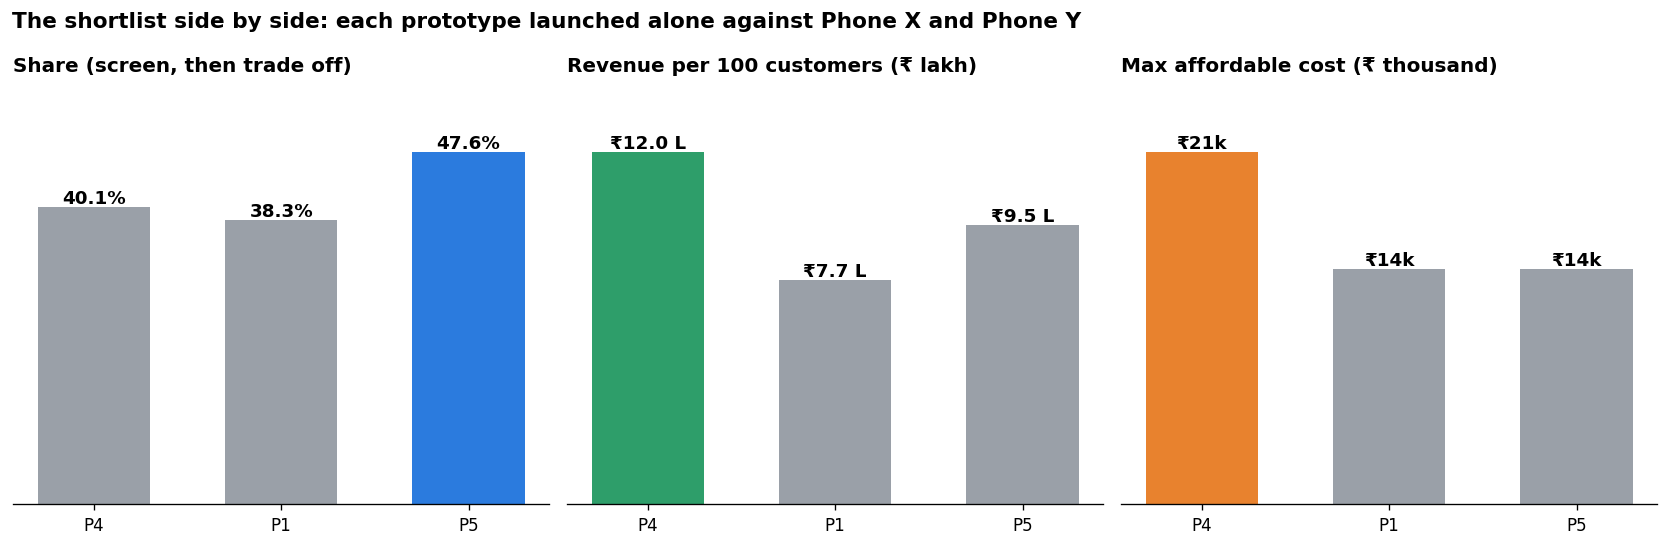

Share leader: P5   Revenue leader: P4   Most room on cost: P4


In [77]:
# ===== 2e (i). Compare the shortlist: share, revenue and cost brief side by side =====

GREEN, BLUE, ORANGE, GREY = "#2e9e6a", "#2b7bde", "#e8822e", "#9aa0a8"
names = res["Prototype"].tolist()
panels = [
    ("Share (screen, then trade off)", res["Share: screen, then trade off"] * 100,
     lambda v: f"{v:.1f}%", BLUE),
    ("Revenue per 100 customers (₹ lakh)", res["Revenue per 100 customers"] / 1e5,
     lambda v: f"₹{v:.1f} L", GREEN),
    ("Max affordable cost (₹ thousand)", res["Max affordable cost"] / 1e3,
     lambda v: f"₹{v:.0f}k", ORANGE),
]

fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))
for ax, (title, vals, fmt, colour) in zip(axes, panels):
    best = vals.values.argmax()
    cols = [colour if i == best else GREY for i in range(len(vals))]
    bars = ax.bar(names, vals.values, color=cols, width=0.6)
    for b, v in zip(bars, vals.values):
        ax.text(b.get_x() + b.get_width() / 2, b.get_height(), fmt(v),
                ha="center", va="bottom", fontsize=11, fontweight="bold")
    ax.set_title(title, fontsize=12, fontweight="bold", loc="left")
    ax.set_ylim(0, vals.max() * 1.2)
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.set_yticks([])
fig.suptitle("The shortlist side by side: each prototype launched alone against "
             "Phone X and Phone Y", fontsize=13, fontweight="bold", x=0.01, ha="left")
plt.tight_layout()
plt.show()

share_lead = res.loc[res["Share: screen, then trade off"].idxmax(), "Prototype"]
rev_lead = res.loc[res["Revenue per 100 customers"].idxmax(), "Prototype"]
cost_room = res.loc[res["Max affordable cost"].idxmax(), "Prototype"]
print(f"Share leader: {share_lead}   Revenue leader: {rev_lead}   "
      f"Most room on cost: {cost_room}")

**How to read this chart**

- Three panels, three measures, the same three prototypes in each. Each prototype is launched on its own against Phone X and Phone Y.
- **Share:** the share of the market it wins once screeners apply their deal-breakers.
- **Revenue per 100 customers:** share × price, for every 100 customers in the market. It puts share and price on one scale.
- **Max affordable cost:** price × (1 − 30% margin), the most it can cost to make.
- In each panel, the coloured bar is the leader on that measure; the others are grey.

**What it shows**

- **No prototype wins all three.** P5 leads on share, and P4 leads on revenue and on room to build.
- **P5 wins the most customers (47.6%).** No screener rules it out, and at ₹20k it is within everyone's price cap.
- **P4 earns the most (₹12.0 lakh per 100 customers),** 26% more than P5, despite a smaller share. Its ₹30k price more than makes up for the customers it loses.
- **P4 also has the most room to build:** up to ₹21k a unit, against ₹14k for P1 and P5. A flagship camera, 512 GB and a 6.8" screen need that headroom.
- **P1 trails on all three.** It sells at P5's price but wins fewer customers, so it earns less.

**The takeaway**

The shortlist doesn't have one winner. It has a choice. **P5 is the share play: more customers, at a price everyone accepts. P4 is the value play: fewer customers, more money, and more room to build.** Which is right depends on what the business needs this launch to do.

#### (ii) Who does each prototype win? Share by segment

The same launches, split by the four customer segments in the data. The bold figure in each row is the prototype that wins that segment.

In [78]:
# ===== 2e (ii). Who does each prototype win? Share by segment =====
seg = cust["segment"]
rows = {}
for proto in SHORTLIST:
    prods = [proto] + RIVALS
    e = np.exp(C * scores[prods])
    e_ok = e.where(PASSES[prods], 0)
    total = e_ok.sum(axis=1)
    p = e_ok.div(total.where(total > 0), axis=0).fillna(0)[proto]
    rows[short[proto]] = p.groupby(seg).mean()

by_seg = pd.DataFrame(rows)
by_seg.loc["All customers"] = res.set_index("Prototype")["Share: screen, then trade off"]
by_seg.insert(0, "Customers", seg.value_counts().reindex(by_seg.index[:-1]).tolist()
              + [len(cust)])

INK, WHITE = "#1f2328", "#ffffff"


def heat(v):
    a = min(max((v - 0.2) / 0.45, 0), 1)
    r, g, b = (int(255 - (255 - c) * a) for c in (168, 200, 240))
    return f"background-color:rgb({r},{g},{b}); color:{INK}"


def best_in_row(row):
    top = row[names].max()
    return ["font-weight:800" if (c in names and row[c] == top) else "" for c in row.index]


styled = (
    by_seg.rename_axis("Segment").reset_index().style
    .hide(axis="index")
    .apply(lambda r: [f"background-color:{WHITE}; color:{INK}"] * len(r), axis=1)
    .map(heat, subset=names)
    .apply(best_in_row, axis=1)
    .format({n: "{:.0%}" for n in names})
    .set_caption("Share each prototype would win in each segment "
                 "(launched alone, screen then trade off)")
    .set_table_styles([
        {"selector": "",
         "props": f"border-collapse:collapse; background-color:{WHITE}; "
                  "font-family:Arial, sans-serif; border:1px solid #d9d6cf"},
        {"selector": "caption",
         "props": f"caption-side:top; font-size:15px; font-weight:700; color:{INK}; "
                  f"background-color:{WHITE}; text-align:left; padding:10px 14px"},
        {"selector": "th",
         "props": f"color:{INK}; background-color:#f1f0ec; font-weight:700; "
                  "text-align:center; padding:8px 14px"},
        {"selector": "td", "props": "text-align:center; padding:7px 14px; font-size:14px; "
                                    "border-bottom:1px solid #e6e4df"},
        {"selector": "td.col0", "props": "font-weight:700; text-align:left"},
    ])
)
display(styled)

for s in by_seg.index[:-1]:
    print(f"{s}: best won by {by_seg.loc[s, names].astype(float).idxmax()}")

Segment,Customers,P4,P1,P5
Battery first,58,37%,44%,56%
Camera lover,74,44%,27%,32%
Power user,79,58%,22%,31%
Value seeker,89,24%,59%,71%
All customers,300,40%,38%,48%


Battery first: best won by P5
Camera lover: best won by P4
Power user: best won by P4
Value seeker: best won by P5


**How to read this table**

- Each row is a customer segment, with the number of customers in it. The last row is the whole market.
- Each column is a shortlisted prototype, launched on its own against Phone X and Phone Y.
- Each cell is the share of that segment the prototype would win. Deeper blue means a bigger share.
- The **bold** figure in each row is the prototype that wins that segment.

**What it shows**

- **The market splits cleanly in two.**
  - **P4 wins the demanding buyers:** power users (58%) and camera lovers (44%), 153 customers in all.
  - **P5 wins the practical buyers:** value seekers (71%) and battery-first buyers (56%), 147 customers in all.
- **The two prototypes barely compete.** Where P4 is strong, P5 is weak, and the other way round. P4 takes only 24% of value seekers; P5 takes only 31% of power users.
- **P1 wins no segment.** It comes second with value seekers (59%) and battery-first buyers (44%), and well behind with the rest. It is a good phone, but never the *best* phone for anyone.
- **P5's lead comes from the biggest segment.** Value seekers are the largest group (89 customers), and P5 wins 71% of them.

**The takeaway**

Averages hide who you are really building for. Across the whole market, P5 and P4 look like rivals. By segment, **they serve different customers: P4 for those who want the best, and P5 for those who want the sensible choice.**

That changes the decision. It is not just "P4 or P5": it can be **P4 and P5**, launched as a range that covers both halves of the market. And P1 goes to the development library: a phone that is everyone's second choice is no one's first.

### Where the analysis stops and judgement starts

The numbers have narrowed six prototypes to a clear set of choices:

| If the business wants to… | Launch | Because |
|---|---|---|
| Win the most customers | **P5** | Highest share (47.6%); no screener rules it out; wins value seekers and battery-first buyers |
| Earn the most per customer | **P4** | Highest revenue (₹12.0 lakh per 100 customers); most room to build (₹21k); wins power users and camera lovers |
| Cover the whole market | **P4 and P5** | They win different segments and barely overlap |

Before anything goes to launch, two checks sit outside this notebook:
1. **Can it be built within its cost brief?** P4 for ₹21,000 or less; P5 for ₹14,000 or less. If engineering can't hit the number, the prototype drops.
2. **Can the business reach the segment?** Real share also depends on awareness, availability/distribution, which this index doesn't capture.

The framework has taken the guesswork out of *what customers value*. **The call on *which* to launch belongs to the business.**

### End of code